# So sánh agent Q learning và agent dựa trên luật trong thương mại điện tử

AGENT02 — Intelligent System Development — 27/10/2026.

Notebook tự chứa mã mẫu, thí nghiệm A–E, phần mở rộng và kết quả thực. Chạy từ đầu đến cuối trong thư mục chứa notebook với Python ≥3.12 theo bộ requirements đã ghim, numpy, matplotlib, IPython. Mỗi code cell có giải thích và mọi hàm đều được mô tả.

Baseline giữ nguyên 5000 episode ×20 bước, alpha=.10, gamma=.90, seed42; evaluation tách riêng 500 episode, Q đóng băng và exploration tắt. Các nhóm nhiều seed dùng 11,22,33,44,55. Phần sáng tạo không thay thế yêu cầu chuẩn.

Lưu ý phương pháp: state mẫu có thể thiếu tính Markov; oracle biết mô hình là chuẩn tham chiếu; số liệu exact là kỳ vọng giải tích, khác số liệu Monte Carlo đo từ mô phỏng. CI chỉ phản ánh năm seed trong mô hình này.

## 01 Thư viện và mô tả chương trình

Nhập NumPy, Matplotlib, pathlib, csv và dataclass. Đây là mã mẫu được cung cấp trong agent02_code.tex.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 01: Nhập thư viện và phạm vi mô phỏng

Nạp dataclass,Path,csv,NumPy và Matplotlib; chuỗi mô tả liệt kê đầu ra và nguyên tắc học RL so với đối thủ luật. Đây là định nghĩa thí nghiệm thương mại điện tử giả lập, các reward là lợi nhuận theo công thức trong code.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [1]:
"""
AGENT02: Reinforcement-Learning-Based Agent vs Rule-Based Agent
================================================================

Course: Intelligent System Development

Run:
    python agent02_experiment.py

Dependencies:
    numpy
    matplotlib

Outputs:
    agent02_results/
        baseline_episode_rewards.csv
        baseline_evaluation.csv
        baseline_evaluation_episodes.csv
        learning_rate_comparison.csv
        exploration_comparison.csv
        multi_seed_summary.csv
        q_tables.txt
        episode_rewards.png
        learning_rate_comparison.png
        exploration_comparison.png

Agents:
    1. RL-based agent: tabular Q-learning
    2. Rule-based agent: fixed if-else policy

The RL agent is trained against a fixed rule-based opponent.
Evaluation freezes the learned Q-table and disables exploration.
"""

from dataclasses import dataclass
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt

## 02 CONFIGURATION

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Config là dataclass gom cấu hình. Nó tự sinh hàm khởi tạo cho số episode, bước, alpha, gamma, epsilon, giá, chi phí, số khách, seed và đường dẫn output. State là bí danh tuple[int,int] cho nhu cầu và hành động trước của đối thủ; nó không bổ sung kiểm tra kiểu lúc chạy.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 02: Cấu hình và không gian trạng thái

Config đặt 5000 episode,20 bước,alpha=.1,gamma=.9,lịch epsilon,giá10/chi phí5/giảm20%,seed42 và500 episode đánh giá. State là type alias tuple[int,int] cho demand và hành động trước đối thủ; chưa phải full-history state của phần mở rộng.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `State`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`Config`**: Dataclass giữ ngân sách episode/bước, alpha, gamma, lịch epsilon, giá/chi phí/giảm giá, khách hàng thấp/cao, seed và đường dẫn. Tạo Config chỉ đặt tham số, chưa chạy thí nghiệm.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [2]:
@dataclass
class Config:
    episodes: int = 5000
    steps_per_episode: int = 20

    alpha: float = 0.10
    gamma: float = 0.90

    epsilon_start: float = 0.20
    epsilon_min: float = 0.02
    epsilon_decay: float = 0.995

    price: float = 10.0
    unit_cost: float = 5.0
    discount_rate: float = 0.20

    low_demand_customers: int = 10
    high_demand_customers: int = 20

    seed: int = 42
    evaluation_episodes: int = 500

    output_dir: str = "agent02_results"


State = tuple[int, int]

## 03 E-COMMERCE ENVIRONMENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **ECommerceEnvironment.__init__**: Tạo RNG riêng, lưu cấu hình và khởi tạo nhu cầu, lịch sử hai hành động.
- **ECommerceEnvironment.reset**: Lấy nhu cầu đầu episode, đưa hai hành động trước về 0; trả quan sát riêng của hai agent.
- **ECommerceEnvironment.get_states**: Đảo chỉ số người bán để mỗi agent nhận nhu cầu chung và hành động trước của đối thủ.
- **ECommerceEnvironment.step**: Kiểm tra hai hành động nhị phân; tính xác suất mua, lấy doanh số nhị thức, tính lợi nhuận; cập nhật lịch sử và nhu cầu sau khi cả hai đã chọn.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 03: Môi trường hai bên chọn đồng thời

ECommerceEnvironment dùng hai action 0/1 chọn trước step. Mua hàng Binomial từ xác suất tuyến tính đã clip; reward=sales*(giá sau giảm-unit_cost). Nhu cầu bước sau rút độc lập. Quan sát thiếu own_previous và số bước còn lại trong bản gốc, trong khi đối thủ luật phản ứng với own_previous của RL ở lần kế.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`ECommerceEnvironment`**: Mô phỏng hai bên chọn đồng thời hành động 0/1. Mỗi bên quan sát demand và hành động trước của đối thủ; xác suất mua .30+.25*d+.15*a-.10*b được clip .05..95, số bán Binomial và reward là lợi nhuận. Nhu cầu bước sau rút độc lập 0/1.
 - **`ECommerceEnvironment.__init__(self, config, seed=None)`**: Lưu config, tạo RNG theo seed được chỉ định và khởi tạo demand/hành động trước bằng 0.
 - **`ECommerceEnvironment.reset(self)`**: Rút demand ngẫu nhiên, đặt lịch sử hành động [0,0], trả quan sát cho hai bên qua get_states. RNG tiếp tục dòng số ngẫu nhiên của môi trường.
 - **`ECommerceEnvironment.get_states(self)`**: Trả hai tuple (demand,hành động trước của đối thủ); phía thứ hai nhận previous_actions[0]. Không tiết lộ hành động hiện tại trước step.
 - **`ECommerceEnvironment.step(self, actions)`**: Kiểm hai hành động trong {0,1}, tính số khách theo demand, rút Binomial cho từng bên và nhân biên lợi nhuận sau giảm giá. Cập nhật previous_actions/demand, trả next_states,rewards,info; hàm không tự quản lý hạn episode.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [3]:
class ECommerceEnvironment:
    """
    Two agents compete in a simplified e-commerce market.

    State:
        (demand, competitor_previous_action)

        demand:
            0 = low demand
            1 = high demand

        competitor_previous_action:
            0 = no discount
            1 = discount

    Action:
        0 = no discount
        1 = discount

    Reward:
        Profit = sales * profit_per_sale
    """

    def __init__(self, config, seed=None):
        self.config = config
        actual_seed = config.seed if seed is None else seed
        self.rng = np.random.default_rng(actual_seed)

        self.demand = 0
        self.previous_actions = [0, 0]

    def reset(self):
        self.demand = int(self.rng.integers(0, 2))
        self.previous_actions = [0, 0]
        return self.get_states()

    def get_states(self):
        return [
            (self.demand, self.previous_actions[1]),
            (self.demand, self.previous_actions[0])
        ]

    def step(self, actions):
        if len(actions) != 2:
            raise ValueError("Exactly two actions are required.")

        if any(action not in (0, 1) for action in actions):
            raise ValueError("Actions must be 0 or 1.")

        rewards = []
        sales_list = []
        conversion_list = []

        if self.demand == 0:
            customers = self.config.low_demand_customers
        else:
            customers = self.config.high_demand_customers

        # Both actions are selected before this function is called.
        # Neither agent observes the other's current action beforehand.
        for i in range(2):
            own_action = actions[i]
            competitor_action = actions[1 - i]

            # Illustrative conversion probability.
            conversion = (
                0.30
                + 0.25 * self.demand
                + 0.15 * own_action
                - 0.10 * competitor_action
            )

            conversion = float(np.clip(
                conversion, 0.05, 0.95
            ))

            # Stochastic number of sales.
            sales = int(self.rng.binomial(
                customers, conversion
            ))

            # Apply a discount only when action = 1.
            effective_price = self.config.price * (
                1.0 - self.config.discount_rate * own_action
            )

            profit_per_sale = (
                effective_price - self.config.unit_cost
            )

            profit = sales * profit_per_sale

            rewards.append(float(profit))
            sales_list.append(sales)
            conversion_list.append(conversion)

        # Store current actions for the next observation.
        self.previous_actions = list(actions)

        # Demand evolves independently of current actions.
        self.demand = int(self.rng.integers(0, 2))

        next_states = self.get_states()

        info = {
            "sales": sales_list,
            "conversion": conversion_list,
            "customers": customers
        }

        return next_states, rewards, info

## 04 REINFORCEMENT-LEARNING-BASED AGENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **QLearningAgent.__init__**: Lưu alpha, gamma, epsilon; tạo RNG riêng và Q-table 2×2×2 bằng 0.
- **QLearningAgent.act**: Epsilon-greedy trong huấn luyện; explore=False bỏ nhánh khám phá; hòa Q được phá ngẫu nhiên bằng RNG của agent.
- **QLearningAgent.learn**: Tính TD target; terminal chỉ dùng reward; các bước khác cộng gamma nhân Q tốt nhất của trạng thái kế.
- **QLearningAgent.greedy_policy**: Xuất một hành động argmax cho mỗi trạng thái. Khi hòa, hàm này chọn chỉ số nhỏ nhất; act dùng phá hòa ngẫu nhiên.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 04: Agent Q-learning tám giá trị

QLearningAgent có bảng [demand,competitor_previous_action,action]. act khám phá epsilon hoặc phá hòa ngẫu nhiên giữa max gần bằng; learn TD có gamma và xử lý terminal. greedy_policy để in dùng argmax đầu, khác quy tắc hòa của act.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`QLearningAgent`**: Bảng Q[2,2,2] chỉ có 8 số, tra theo demand/lịch sử đối thủ/action. act epsilon-greedy phá hòa ngẫu nhiên; learn cập nhật TD với gamma, terminal không bootstrap. greedy_policy dùng argmax chỉ số đầu khi hòa.
 - **`QLearningAgent.__init__(self, alpha=0.1, gamma=0.9, epsilon=0.2, seed=123)`**: Lưu alpha/gamma/epsilon, tạo RNG và bảng Q toàn 0. Seed agent tách với seed môi trường ở hàm train.
 - **`QLearningAgent.act(self, state, explore=True)`**: Nếu explore và RNG < epsilon thì chọn 0/1 ngẫu nhiên; nếu không thì chọn ngẫu nhiên giữa các giá trị np.isclose với max Q của state.
 - **`QLearningAgent.learn(self, state, action, reward, next_state, terminal=False)`**: Đọc old Q, tính target=reward ở terminal hoặc reward+gamma*max Q(next_state), rồi gán old+alpha*(target-old). Chỉ cập nhật một cell bảng.
 - **`QLearningAgent.greedy_policy(self)`**: Duyệt bốn trạng thái và trả dict state→np.argmax(Q). Bảng in này có quy tắc hòa điểm khác act (argmax đầu thay vì chọn ngẫu nhiên).

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [4]:
class QLearningAgent:
    """
    Tabular Q-learning agent.

    Q[demand, competitor_previous_action, action]

    There are:
        2 demand states
        2 competitor-action states
        2 possible actions

    Total Q-values = 2 * 2 * 2 = 8
    """

    def __init__(
        self,
        alpha=0.10,
        gamma=0.90,
        epsilon=0.20,
        seed=123
    ):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

        self.rng = np.random.default_rng(seed)

        self.q = np.zeros((2, 2, 2), dtype=float)

    def act(self, state, explore=True):
        demand, competitor_previous_action = state

        # Exploration.
        if explore and self.rng.random() < self.epsilon:
            return int(self.rng.integers(0, 2))

        # Exploitation.
        values = self.q[demand, competitor_previous_action]

        # Random tie-breaking when action values are equal.
        best_actions = np.flatnonzero(
            np.isclose(values, np.max(values))
        )

        return int(self.rng.choice(best_actions))

    def learn(
        self,
        state,
        action,
        reward,
        next_state,
        terminal=False
    ):
        demand, competitor_previous_action = state
        next_demand, next_competitor_action = next_state

        old_value = self.q[
            demand, competitor_previous_action, action
        ]

        if terminal:
            target = reward
        else:
            best_future_value = np.max(
                self.q[next_demand, next_competitor_action]
            )

            target = (
                reward + self.gamma * best_future_value
            )

        # Q-learning update.
        self.q[
            demand, competitor_previous_action, action
        ] = old_value + self.alpha * (
            target - old_value
        )

    def greedy_policy(self):
        policy = {}

        for demand in range(2):
            for competitor_action in range(2):
                state = (demand, competitor_action)

                policy[state] = int(
                    np.argmax(self.q[demand, competitor_action])
                )

        return policy

## 05 RULE-BASED AGENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **RuleBasedAgent.act**: Ba nhánh if/elif/else đúng bảng luật của đề; không cập nhật từ reward.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 05: Đối thủ theo luật cố định

RuleBasedAgent trả giảm giá chỉ khi nhu cầu cao và đối thủ đã giảm ở lượt trước. Không có học reward hay đổi chính sách, giúp cố định một phần môi trường cho RL. Trạng thái của mỗi bên dùng lịch sử phía còn lại.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`RuleBasedAgent`**: Luật cố định: chỉ giảm giá khi demand cao và đối thủ đã giảm ở bước trước; các trường hợp khác giữ giá. Không có learn hay cập nhật tham số.
 - **`RuleBasedAgent.act(self, state)`**: Giải nén demand/competitor_previous_action rồi trả 1 duy nhất ở (1,1), ngược lại 0.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [5]:
class RuleBasedAgent:
    """
    Fixed policy:

    Rule 1:
        Low demand -> no discount.

    Rule 2:
        High demand and competitor previously discounted
        -> offer a discount.

    Rule 3:
        High demand and competitor did not previously discount
        -> no discount.

    This agent does not learn from rewards.
    """

    def act(self, state):
        demand, competitor_previous_action = state

        if demand == 0:
            return 0

        elif demand == 1 and competitor_previous_action == 1:
            return 1

        else:
            return 0

## 06 TRAIN THE RL AGENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **train_rl_against_rule**: Tạo môi trường và hai agent, giảm epsilon theo episode, chọn đồng thời, cập nhật Q duy nhất cho RL; trả agent và log từng episode.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 06: Huấn luyện chống đối thủ luật

train_rl_against_rule cho phép ghi đè alpha/lịch epsilon; mỗi episode reset môi trường và giảm epsilon. Hai bên chọn trước step, chỉ RL được learn, bước cuối terminal để không bootstrap qua reset. Trả agent và log tổng reward/reward mỗi bước/epsilon/alpha.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`train_rl_against_rule(config, seed, alpha=None, epsilon_start=None, epsilon_min=None, epsilon_decay=None)`**: Tạo môi trường, Q agent và đối thủ luật cố định. Mỗi episode giảm epsilon theo max(min,start*decay**episode), chạy các bước đồng thời và learn chỉ phía RL; bước cuối đánh terminal. Trả agent cùng reward/lịch epsilon từng episode.
 - **Helper dùng lại `ECommerceEnvironment`**: Mô phỏng hai bên chọn đồng thời hành động 0/1. Mỗi bên quan sát demand và hành động trước của đối thủ; xác suất mua .30+.25*d+.15*a-.10*b được clip .05..95, số bán Binomial và reward là lợi nhuận. Nhu cầu bước sau rút độc lập 0/1.
 - **Helper dùng lại `QLearningAgent`**: Bảng Q[2,2,2] chỉ có 8 số, tra theo demand/lịch sử đối thủ/action. act epsilon-greedy phá hòa ngẫu nhiên; learn cập nhật TD với gamma, terminal không bootstrap. greedy_policy dùng argmax chỉ số đầu khi hòa.
 - **Helper dùng lại `RuleBasedAgent`**: Luật cố định: chỉ giảm giá khi demand cao và đối thủ đã giảm ở bước trước; các trường hợp khác giữ giá. Không có learn hay cập nhật tham số.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [6]:
def train_rl_against_rule(
    config,
    seed,
    alpha=None,
    epsilon_start=None,
    epsilon_min=None,
    epsilon_decay=None
):
    """
    Train one RL agent against a fixed rule-based opponent.

    The opponent's policy remains unchanged during training.
    """

    alpha = config.alpha if alpha is None else alpha

    epsilon_start = (
        config.epsilon_start
        if epsilon_start is None
        else epsilon_start
    )

    epsilon_min = (
        config.epsilon_min
        if epsilon_min is None
        else epsilon_min
    )

    epsilon_decay = (
        config.epsilon_decay
        if epsilon_decay is None
        else epsilon_decay
    )

    env = ECommerceEnvironment(config, seed=seed)

    rl_agent = QLearningAgent(
        alpha=alpha,
        gamma=config.gamma,
        epsilon=epsilon_start,
        seed=seed + 10_000
    )

    rule_agent = RuleBasedAgent()

    episode_results = []

    for episode in range(config.episodes):

        # Decrease exploration as training progresses.
        rl_agent.epsilon = max(
            epsilon_min,
            epsilon_start * epsilon_decay ** episode
        )

        states = env.reset()

        episode_rewards = [0.0, 0.0]

        for step in range(config.steps_per_episode):

            # Both agents choose actions before the environment changes.
            rl_action = rl_agent.act(
                states[0], explore=True
            )

            rule_action = rule_agent.act(states[1])

            actions = [rl_action, rule_action]

            next_states, rewards, info = env.step(actions)

            terminal = (
                step == config.steps_per_episode - 1
            )

            rl_agent.learn(
                state=states[0],
                action=rl_action,
                reward=rewards[0],
                next_state=next_states[0],
                terminal=terminal
            )

            episode_rewards[0] += rewards[0]
            episode_rewards[1] += rewards[1]

            states = next_states

        episode_results.append({
            "episode": episode + 1,
            "rl_episode_reward": episode_rewards[0],
            "rule_episode_reward": episode_rewards[1],
            "rl_mean_reward_per_step": (
                episode_rewards[0]
                / config.steps_per_episode
            ),
            "rule_mean_reward_per_step": (
                episode_rewards[1]
                / config.steps_per_episode
            ),
            "epsilon": rl_agent.epsilon,
            "alpha": alpha
        })

    return rl_agent, episode_results

## 07 SEPARATE POLICY EVALUATION

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **evaluate_pair**: Tạo môi trường seed mới, gọi act với explore=False và không gọi learn; cộng reward và số lượng hành động, trả bảng tổng hợp cùng log evaluation.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 07: Đánh giá đóng băng tách khỏi học

evaluate_pair mở môi trường seed riêng, gọi RL act(explore=False) và luật cố định, không learn. Tính tổng/lợi nhuận mỗi bước và số/tỷ lệ giảm giá cho hai bên; trả summary và từng episode. Nếu Q hòa, hành động vẫn được rút ngẫu nhiên bằng RNG agent.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`evaluate_pair(config, rl_agent, episodes=None, seed=900000)`**: Tạo môi trường với seed đánh giá, gọi act(explore=False) và không gọi learn; đối thủ giữ luật. Tổng reward và số hành động được chia tổng bước để tạo summary; vẫn phá hòa Q ngẫu nhiên nếu có. Trả summary và log episode.
 - **Helper dùng lại `ECommerceEnvironment`**: Mô phỏng hai bên chọn đồng thời hành động 0/1. Mỗi bên quan sát demand và hành động trước của đối thủ; xác suất mua .30+.25*d+.15*a-.10*b được clip .05..95, số bán Binomial và reward là lợi nhuận. Nhu cầu bước sau rút độc lập 0/1.
 - **Helper dùng lại `RuleBasedAgent`**: Luật cố định: chỉ giảm giá khi demand cao và đối thủ đã giảm ở bước trước; các trường hợp khác giữ giá. Không có learn hay cập nhật tham số.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [7]:
def evaluate_pair(
    config,
    rl_agent,
    episodes=None,
    seed=900_000
):
    """
    Evaluate a frozen RL policy against the fixed rule-based agent.

    Important:
        - No Q-table updates occur.
        - RL exploration is disabled.
        - Evaluation uses a separate environment random seed.
    """

    if episodes is None:
        episodes = config.evaluation_episodes

    env = ECommerceEnvironment(config, seed=seed)

    rule_agent = RuleBasedAgent()

    total_rewards = np.zeros(2, dtype=float)
    action_counts = np.zeros((2, 2), dtype=int)

    episode_results = []

    for episode in range(episodes):

        states = env.reset()
        rewards_this_episode = [0.0, 0.0]

        for _ in range(config.steps_per_episode):

            # Greedy RL policy: no exploration.
            rl_action = rl_agent.act(
                states[0], explore=False
            )

            rule_action = rule_agent.act(states[1])

            actions = [rl_action, rule_action]

            next_states, rewards, info = env.step(actions)

            for i in range(2):
                total_rewards[i] += rewards[i]
                rewards_this_episode[i] += rewards[i]
                action_counts[i, actions[i]] += 1

            states = next_states

        episode_results.append({
            "episode": episode + 1,
            "rl_reward": rewards_this_episode[0],
            "rule_reward": rewards_this_episode[1],
            "rl_mean_reward_per_step": (
                rewards_this_episode[0]
                / config.steps_per_episode
            ),
            "rule_mean_reward_per_step": (
                rewards_this_episode[1]
                / config.steps_per_episode
            )
        })

    total_steps = episodes * config.steps_per_episode

    summary = []

    for i, name in enumerate(["RL", "Rule-based"]):
        summary.append({
            "agent": name,
            "total_reward": total_rewards[i],
            "mean_reward_per_step": (
                total_rewards[i] / total_steps
            ),
            "no_discount_actions": int(action_counts[i, 0]),
            "discount_actions": int(action_counts[i, 1]),
            "discount_action_rate": (
                action_counts[i, 1] / total_steps
            )
        })

    return summary, episode_results

## 08 CSV AND Q-TABLE OUTPUT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **write_csv**: Ghi danh sách dictionary với header lấy từ hàng đầu, UTF-8 và newline rỗng; bỏ qua dữ liệu rỗng.
- **save_q_table**: Ghi 8 giá trị Q và hành động greedy của 4 trạng thái ra file văn bản có thể kiểm tra.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 08: Xuất CSV và đọc bảng Q

write_csv ghi rows theo cột hàng đầu; save_q_table xuất Q0/Q1/greedy action cho bốn state. Đây là file kết quả cục bộ giúp kiểm tay; không tự tạo thư mục cha và không gọi train trong các helper này.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`write_csv(filepath, rows)`**: Nếu rows rỗng thì không ghi; nếu có thì lấy khóa dòng đầu làm cột, ghi header và toàn bộ rows bằng UTF-8. File cùng tên bị ghi lại.
 - **`save_q_table(filepath, agent)`**: Xuất Q0/Q1 và greedy action cho bốn trạng thái vào file văn bản để đọc tay. Chỉ là ảnh chụp bảng hiện tại, không phải checkpoint dạng nhị phân.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [8]:
def write_csv(filepath, rows):
    if not rows:
        return

    with open(
        filepath, "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(rows)


def save_q_table(filepath, agent):
    with open(filepath, "w", encoding="utf-8") as file:
        file.write(
            "Q-table: Q[demand, competitor_previous_action, action]\n"
        )
        file.write(
            "Action 0 = no discount; Action 1 = discount\n\n"
        )

        for demand in range(2):
            for competitor_action in range(2):

                q0 = agent.q[demand, competitor_action, 0]
                q1 = agent.q[demand, competitor_action, 1]

                best_action = int(
                    np.argmax(
                        agent.q[demand, competitor_action]
                    )
                )

                file.write(
                    f"State=({demand}, {competitor_action}) | "
                    f"Q0={q0:.6f} | Q1={q1:.6f} | "
                    f"Greedy action={best_action}\n"
                )

## 09 PLOTS

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **moving_average**: Dùng convolution với kernel đều để làm mượt; trả chuỗi gốc nếu chưa đủ cửa sổ.
- **plot_training_rewards**: Vẽ đường reward thô và trung bình trượt cho RL và Rule; lưu PNG rồi đóng hình để tránh giữ bộ nhớ.
- **plot_bar_comparison**: Vẽ cột theo khóa nhãn và khóa giá trị; dùng lại cho learning rate và exploration.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 09: Các hàm vẽ của thí nghiệm gốc

moving_average làm mượt bằng convolution valid; plot_training_rewards vẽ reward/bước thô và trung bình trượt, plot_bar_comparison vẽ cột từ khóa được truyền. Hình train chứa khám phá, còn hình đánh giá dùng summary đóng băng; cần đọc nhãn trục.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`moving_average(values, window=100)`**: Đổi values sang NumPy, nếu ngắn hơn window thì trả nguyên chuỗi; đủ dài thì convolve với vector 1/window ở chế độ valid. Đường làm mượt có ít điểm hơn dữ liệu gốc.
 - **`plot_training_rewards(rows, filepath)`**: Vẽ reward/bước của RL và luật qua episode và thêm trung bình trượt khi đủ dài. Lưu PNG rồi đóng figure; reward này còn chứa hành vi khám phá trong lúc học.
 - **`plot_bar_comparison(rows, label_key, value_key, filepath, title)`**: Dùng label_key/value_key lấy nhãn/giá trị từ rows, vẽ cột, đặt tiêu đề và lưu PNG. Hàm chỉ biểu diễn số liệu truyền vào.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [9]:
def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    kernel = np.ones(window) / window

    return np.convolve(
        values, kernel, mode="valid"
    )


def plot_training_rewards(rows, filepath):
    episodes = [
        row["episode"] for row in rows
    ]

    rl_rewards = [
        row["rl_mean_reward_per_step"] for row in rows
    ]

    rule_rewards = [
        row["rule_mean_reward_per_step"] for row in rows
    ]

    plt.figure(figsize=(10, 6))

    plt.plot(
        episodes, rl_rewards,
        alpha=0.25, label="RL training reward"
    )

    plt.plot(
        episodes, rule_rewards,
        alpha=0.25, label="Rule-based reward"
    )

    window = min(100, max(10, len(rows) // 20))

    if len(rows) >= window:
        plt.plot(
            episodes[window - 1:],
            moving_average(rl_rewards, window),
            linewidth=2,
            label=f"RL moving average ({window})"
        )

        plt.plot(
            episodes[window - 1:],
            moving_average(rule_rewards, window),
            linewidth=2,
            label=f"Rule moving average ({window})"
        )

    plt.xlabel("Training episode")
    plt.ylabel("Mean reward per step")
    plt.title("RL Training Against a Rule-Based Agent")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filepath, dpi=160)
    plt.close()


def plot_bar_comparison(
    rows, label_key, value_key, filepath, title
):
    labels = [str(row[label_key]) for row in rows]
    values = [row[value_key] for row in rows]

    plt.figure(figsize=(8, 5))
    plt.bar(labels, values)

    plt.xlabel(label_key.replace("_", " ").title())
    plt.ylabel(value_key.replace("_", " ").title())
    plt.title(title)

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(filepath, dpi=160)
    plt.close()

## 10 BASELINE EXPERIMENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **run_baseline**: Huấn luyện đúng cấu hình chuẩn, lưu log/Q/hình, đánh giá 500 episode với seed 500042 và in policy.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 10: Gói thí nghiệm baseline

run_baseline học cấu hình gốc, lưu training CSV/Q/PNG rồi đánh giá seed+500000. In lợi nhuận/tỷ lệ giảm và greedy policy, trả agent. Seed cố định giúp tái lập trong cùng môi trường phần mềm, chưa tạo khoảng tin cậy qua nhiều lần học.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`run_baseline(config, output_dir)`**: Huấn luyện cấu hình gốc, xuất reward/Q/đường học, đánh giá đóng băng bằng seed+500000, lưu CSV và in greedy policy. Trả agent đã học.
 - **Helper dùng lại `evaluate_pair`**: Tạo môi trường với seed đánh giá, gọi act(explore=False) và không gọi learn; đối thủ giữ luật. Tổng reward và số hành động được chia tổng bước để tạo summary; vẫn phá hòa Q ngẫu nhiên nếu có. Trả summary và log episode.
 - **Helper dùng lại `plot_training_rewards`**: Vẽ reward/bước của RL và luật qua episode và thêm trung bình trượt khi đủ dài. Lưu PNG rồi đóng figure; reward này còn chứa hành vi khám phá trong lúc học.
 - **Helper dùng lại `save_q_table`**: Xuất Q0/Q1 và greedy action cho bốn trạng thái vào file văn bản để đọc tay. Chỉ là ảnh chụp bảng hiện tại, không phải checkpoint dạng nhị phân.
 - **Helper dùng lại `train_rl_against_rule`**: Tạo môi trường, Q agent và đối thủ luật cố định. Mỗi episode giảm epsilon theo max(min,start*decay**episode), chạy các bước đồng thời và learn chỉ phía RL; bước cuối đánh terminal. Trả agent cùng reward/lịch epsilon từng episode.
 - **Helper dùng lại `write_csv`**: Nếu rows rỗng thì không ghi; nếu có thì lấy khóa dòng đầu làm cột, ghi header và toàn bộ rows bằng UTF-8. File cùng tên bị ghi lại.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [10]:
def run_baseline(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 1: BASELINE")
    print("=" * 60)

    agent, training_rows = train_rl_against_rule(
        config, seed=config.seed
    )

    write_csv(
        output_dir / "baseline_episode_rewards.csv",
        training_rows
    )

    save_q_table(
        output_dir / "q_tables.txt", agent
    )

    plot_training_rewards(
        training_rows,
        output_dir / "episode_rewards.png"
    )

    summary, eval_rows = evaluate_pair(
        config,
        agent,
        episodes=config.evaluation_episodes,
        seed=config.seed + 500_000
    )

    write_csv(
        output_dir / "baseline_evaluation.csv",
        summary
    )

    write_csv(
        output_dir / "baseline_evaluation_episodes.csv",
        eval_rows
    )

    print("\nSeparate evaluation results:")

    for row in summary:
        print(
            f"{row['agent']:12s} | "
            f"mean reward/step = "
            f"{row['mean_reward_per_step']:.4f} | "
            f"discount rate = "
            f"{row['discount_action_rate']:.3f}"
        )

    print("\nLearned greedy policy:")

    for state, action in agent.greedy_policy().items():
        action_name = (
            "DISCOUNT" if action == 1
            else "NO DISCOUNT"
        )
        print(f"State {state}: {action_name}")

    return agent

## 11 LEARNING-RATE EXPERIMENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **run_learning_rate_experiment**: Chỉ đổi alpha trong ba mức 0.01, 0.10, 0.50; giữ seed train/eval trong nhóm và xuất kết quả đánh giá.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 11: Thay learning rate

run_learning_rate_experiment lặp .01/.10/.50 và giữ cùng seed train+1000/eval+600000. Lưu reward RL và discount action rate rồi vẽ cột. Đây là một seed cho mỗi alpha trong hàm gốc, nên chênh lệch chưa mô tả biến thiên giữa seed.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`run_learning_rate_experiment(config, output_dir)`**: Lặp alpha=.01,.10,.50, cùng seed train và seed đánh giá giữa các mức; giữ tham số còn lại từ config, xuất CSV/biểu đồ. Mỗi mức trong hàm gốc là một seed, không tự có CI qua nhiều seed.
 - **Helper dùng lại `evaluate_pair`**: Tạo môi trường với seed đánh giá, gọi act(explore=False) và không gọi learn; đối thủ giữ luật. Tổng reward và số hành động được chia tổng bước để tạo summary; vẫn phá hòa Q ngẫu nhiên nếu có. Trả summary và log episode.
 - **Helper dùng lại `plot_bar_comparison`**: Dùng label_key/value_key lấy nhãn/giá trị từ rows, vẽ cột, đặt tiêu đề và lưu PNG. Hàm chỉ biểu diễn số liệu truyền vào.
 - **Helper dùng lại `train_rl_against_rule`**: Tạo môi trường, Q agent và đối thủ luật cố định. Mỗi episode giảm epsilon theo max(min,start*decay**episode), chạy các bước đồng thời và learn chỉ phía RL; bước cuối đánh terminal. Trả agent cùng reward/lịch epsilon từng episode.
 - **Helper dùng lại `write_csv`**: Nếu rows rỗng thì không ghi; nếu có thì lấy khóa dòng đầu làm cột, ghi header và toàn bộ rows bằng UTF-8. File cùng tên bị ghi lại.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [11]:
def run_learning_rate_experiment(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 2: LEARNING RATE")
    print("=" * 60)

    results = []

    for alpha in [0.01, 0.10, 0.50]:

        agent, _ = train_rl_against_rule(
            config,
            seed=config.seed + 1000,
            alpha=alpha
        )

        summary, _ = evaluate_pair(
            config,
            agent,
            episodes=config.evaluation_episodes,
            seed=config.seed + 600_000
        )

        rl_result = next(
            row for row in summary
            if row["agent"] == "RL"
        )

        results.append({
            "alpha": alpha,
            "rl_mean_reward_per_step":
                rl_result["mean_reward_per_step"],
            "rl_discount_action_rate":
                rl_result["discount_action_rate"]
        })

        print(
            f"alpha={alpha:.2f} | "
            f"evaluation reward/step="
            f"{rl_result['mean_reward_per_step']:.4f}"
        )

    write_csv(
        output_dir / "learning_rate_comparison.csv",
        results
    )

    plot_bar_comparison(
        results,
        "alpha",
        "rl_mean_reward_per_step",
        output_dir / "learning_rate_comparison.png",
        "Effect of Learning Rate"
    )

    return results

## 12 EXPLORATION EXPERIMENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **run_exploration_experiment**: Chạy ba lịch low/baseline/high của tài liệu bổ sung; mọi đánh giá đều tắt exploration.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 12: Thay lịch khám phá

run_exploration_experiment so low/medium/high theo bộ epsilon_start/min/decay trong code. Mỗi cấu hình học mới và đánh giá tách rồi lưu CSV/hình; phải đọc cả ba thành phần lịch thay vì xem start như tham số duy nhất.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`run_exploration_experiment(config, output_dir)`**: Lặp ba lịch khám phá low/medium/high đã định nghĩa, train và đánh giá riêng từng lịch, xuất reward và tỷ lệ giảm giá. Đây là thay cả lịch epsilon, cần đọc đủ start/min/decay.
 - **Helper dùng lại `evaluate_pair`**: Tạo môi trường với seed đánh giá, gọi act(explore=False) và không gọi learn; đối thủ giữ luật. Tổng reward và số hành động được chia tổng bước để tạo summary; vẫn phá hòa Q ngẫu nhiên nếu có. Trả summary và log episode.
 - **Helper dùng lại `plot_bar_comparison`**: Dùng label_key/value_key lấy nhãn/giá trị từ rows, vẽ cột, đặt tiêu đề và lưu PNG. Hàm chỉ biểu diễn số liệu truyền vào.
 - **Helper dùng lại `train_rl_against_rule`**: Tạo môi trường, Q agent và đối thủ luật cố định. Mỗi episode giảm epsilon theo max(min,start*decay**episode), chạy các bước đồng thời và learn chỉ phía RL; bước cuối đánh terminal. Trả agent cùng reward/lịch epsilon từng episode.
 - **Helper dùng lại `write_csv`**: Nếu rows rỗng thì không ghi; nếu có thì lấy khóa dòng đầu làm cột, ghi header và toàn bộ rows bằng UTF-8. File cùng tên bị ghi lại.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [12]:
def run_exploration_experiment(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 3: EXPLORATION")
    print("=" * 60)

    settings = [
        ("low", 0.05, 0.02, 0.999),
        ("baseline", 0.20, 0.02, 0.995),
        ("high", 0.50, 0.05, 0.995)
    ]

    results = []

    for name, eps_start, eps_min, eps_decay in settings:

        agent, _ = train_rl_against_rule(
            config,
            seed=config.seed + 2000,
            epsilon_start=eps_start,
            epsilon_min=eps_min,
            epsilon_decay=eps_decay
        )

        summary, _ = evaluate_pair(
            config,
            agent,
            episodes=config.evaluation_episodes,
            seed=config.seed + 700_000
        )

        rl_result = next(
            row for row in summary
            if row["agent"] == "RL"
        )

        results.append({
            "exploration_setting": name,
            "epsilon_start": eps_start,
            "epsilon_min": eps_min,
            "epsilon_decay": eps_decay,
            "rl_mean_reward_per_step":
                rl_result["mean_reward_per_step"],
            "rl_discount_action_rate":
                rl_result["discount_action_rate"]
        })

        print(
            f"{name:8s} | "
            f"evaluation reward/step="
            f"{rl_result['mean_reward_per_step']:.4f}"
        )

    write_csv(
        output_dir / "exploration_comparison.csv",
        results
    )

    plot_bar_comparison(
        results,
        "exploration_setting",
        "rl_mean_reward_per_step",
        output_dir / "exploration_comparison.png",
        "Effect of Exploration Schedule"
    )

    return results

## 13 MULTIPLE-SEED EXPERIMENT

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **run_multi_seed_experiment**: Lặp baseline với seed 11,22,33,44,55; tính mean và SD mẫu ddof=1 của reward giữa seed.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 13: Độ biến thiên qua năm seed

run_multi_seed_experiment học seed11/22/33/44/55, mỗi model đánh giá bằng seed+800000. Lưu reward/tỷ lệ giảm của hai bên và in mean/SD ddof=1. Mỗi dòng seed đại diện một lần train riêng, không phải từng bước giao dịch.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`run_multi_seed_experiment(config, output_dir)`**: Dùng seed 11,22,33,44,55 để train độc lập, đánh giá từng agent, xuất summary và in trung bình/SD mẫu. SD phản ánh biến thiên giữa các lần học trong mô phỏng.
 - **Helper dùng lại `evaluate_pair`**: Tạo môi trường với seed đánh giá, gọi act(explore=False) và không gọi learn; đối thủ giữ luật. Tổng reward và số hành động được chia tổng bước để tạo summary; vẫn phá hòa Q ngẫu nhiên nếu có. Trả summary và log episode.
 - **Helper dùng lại `train_rl_against_rule`**: Tạo môi trường, Q agent và đối thủ luật cố định. Mỗi episode giảm epsilon theo max(min,start*decay**episode), chạy các bước đồng thời và learn chỉ phía RL; bước cuối đánh terminal. Trả agent cùng reward/lịch epsilon từng episode.
 - **Helper dùng lại `write_csv`**: Nếu rows rỗng thì không ghi; nếu có thì lấy khóa dòng đầu làm cột, ghi header và toàn bộ rows bằng UTF-8. File cùng tên bị ghi lại.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [13]:
def run_multi_seed_experiment(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 4: MULTIPLE RANDOM SEEDS")
    print("=" * 60)

    seeds = [11, 22, 33, 44, 55]
    results = []

    for seed in seeds:

        agent, _ = train_rl_against_rule(
            config, seed=seed
        )

        summary, _ = evaluate_pair(
            config,
            agent,
            episodes=config.evaluation_episodes,
            seed=seed + 800_000
        )

        for row in summary:
            results.append({
                "seed": seed,
                "agent": row["agent"],
                "mean_reward_per_step":
                    row["mean_reward_per_step"],
                "discount_action_rate":
                    row["discount_action_rate"]
            })

    write_csv(
        output_dir / "multi_seed_summary.csv",
        results
    )

    print("\nMean and standard deviation across seeds:")

    for name in ["RL", "Rule-based"]:

        values = [
            row["mean_reward_per_step"]
            for row in results
            if row["agent"] == name
        ]

        print(
            f"{name:12s} | "
            f"mean={np.mean(values):.4f} | "
            f"std={np.std(values, ddof=1):.4f} | "
            f"n={len(values)}"
        )

    return results

## 14 MAIN PROGRAM

Khối mã mẫu giữ nguyên logic để làm đường chuẩn; mô tả chức năng từng hàm ngay bên dưới.

Giải thích từng hàm

- **main**: Tạo thư mục output, in cấu hình và điều phối bốn nhóm thí nghiệm gốc.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 14: Hàm điều khiển các thí nghiệm gốc

main tạo Config và thư mục output_dir rồi gọi lần lượt bốn thí nghiệm trên. Các lời in mô tả ngân sách/vị trí file; định nghĩa main chưa chạy thân hàm cho tới cell kế tiếp.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`main()`**: Tạo Config và thư mục đầu ra, lần lượt gọi baseline, learning-rate, exploration, multi-seed rồi in vị trí kết quả. Gọi main() thực sự chạy toàn bộ các vòng mô phỏng này.
 - **Helper dùng lại `Config`**: Dataclass giữ ngân sách episode/bước, alpha, gamma, lịch epsilon, giá/chi phí/giảm giá, khách hàng thấp/cao, seed và đường dẫn. Tạo Config chỉ đặt tham số, chưa chạy thí nghiệm.
 - **Helper dùng lại `run_baseline`**: Huấn luyện cấu hình gốc, xuất reward/Q/đường học, đánh giá đóng băng bằng seed+500000, lưu CSV và in greedy policy. Trả agent đã học.
 - **Helper dùng lại `run_exploration_experiment`**: Lặp ba lịch khám phá low/medium/high đã định nghĩa, train và đánh giá riêng từng lịch, xuất reward và tỷ lệ giảm giá. Đây là thay cả lịch epsilon, cần đọc đủ start/min/decay.
 - **Helper dùng lại `run_learning_rate_experiment`**: Lặp alpha=.01,.10,.50, cùng seed train và seed đánh giá giữa các mức; giữ tham số còn lại từ config, xuất CSV/biểu đồ. Mỗi mức trong hàm gốc là một seed, không tự có CI qua nhiều seed.
 - **Helper dùng lại `run_multi_seed_experiment`**: Dùng seed 11,22,33,44,55 để train độc lập, đánh giá từng agent, xuất summary và in trung bình/SD mẫu. SD phản ánh biến thiên giữa các lần học trong mô phỏng.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [14]:
def main():
    config = Config()

    output_dir = Path(config.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 60)
    print("AGENT02: RL AGENT VS RULE-BASED AGENT")
    print("=" * 60)

    print(f"Episodes: {config.episodes}")
    print(f"Steps per episode: {config.steps_per_episode}")
    print(f"Evaluation episodes: {config.evaluation_episodes}")
    print(f"Random seed: {config.seed}")
    print(f"Output directory: {output_dir.resolve()}")

    run_baseline(config, output_dir)

    run_learning_rate_experiment(
        config, output_dir
    )

    run_exploration_experiment(
        config, output_dir
    )

    run_multi_seed_experiment(
        config, output_dir
    )

    print("\n" + "=" * 60)
    print("ALL EXPERIMENTS COMPLETED")
    print("=" * 60)

    print(f"Results saved to: {output_dir.resolve()}")

    print("\nUse the CSV files and PNG figures in the AGENT02 report.")

## 15 Chạy toàn bộ thí nghiệm mẫu

Thực hiện bốn nhóm của mã mẫu. Kết quả ghi vào agent02_results; stdout dưới cell là kết quả chạy thực, không phải số dự kiến.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 15: Chạy toàn bộ phần baseline

Lệnh main() không có đối số dùng cấu hình mặc định, thực sự học/đánh giá và ghi lại CSV/PNG/Q. Cần chạy các cell định nghĩa trước; thời gian có thể dài vì gồm nhiều seed/tham số. Các output đang lưu là kết quả lần thực thi trước, chưa được tạo lại khi chỉ đọc notebook.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **Helper dùng lại `main`**: Tạo Config và thư mục đầu ra, lần lượt gọi baseline, learning-rate, exploration, multi-seed rồi in vị trí kết quả. Gọi main() thực sự chạy toàn bộ các vòng mô phỏng này.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [15]:
main()

AGENT02: RL AGENT VS RULE-BASED AGENT
Episodes: 5000
Steps per episode: 20
Evaluation episodes: 500
Random seed: 42
Output directory: E:\WINDOW\Project\intelligent-system-assignment-01\ASIGNMENT-AGENT_02\agent02_results

EXPERIMENT 1: BASELINE



Separate evaluation results:
RL           | mean reward/step = 35.1275 | discount rate = 0.000
Rule-based   | mean reward/step = 34.9685 | discount rate = 0.000

Learned greedy policy:
State (0, 0): NO DISCOUNT
State (0, 1): DISCOUNT
State (1, 0): NO DISCOUNT
State (1, 1): DISCOUNT

EXPERIMENT 2: LEARNING RATE


alpha=0.01 | evaluation reward/step=35.2475


alpha=0.10 | evaluation reward/step=35.2475


alpha=0.50 | evaluation reward/step=28.5085



EXPERIMENT 3: EXPLORATION


low      | evaluation reward/step=35.1045


baseline | evaluation reward/step=35.1045


high     | evaluation reward/step=35.1045



EXPERIMENT 4: MULTIPLE RANDOM SEEDS



Mean and standard deviation across seeds:
RL           | mean=34.8919 | std=0.3132 | n=5
Rule-based   | mean=34.9321 | std=0.2496 | n=5

ALL EXPERIMENTS COMPLETED
Results saved to: E:\WINDOW\Project\intelligent-system-assignment-01\ASIGNMENT-AGENT_02\agent02_results

Use the CSV files and PNG figures in the AGENT02 report.


## 16 Kỳ vọng giải tích và quy hoạch động

Bổ sung kiểm tra cấu hình và oracle; full state gồm nhu cầu cùng hai hành động trước. Oracle dùng gamma=1 để tối ưu tổng profit hữu hạn.

Giải thích từng hàm

- **validate_config**: Phát hiện cấu hình không hợp lệ trước khi chạy; trả lỗi rõ ràng thay vì tạo số liệu không có nghĩa.
- **expected_profit**: Tính kỳ vọng lợi nhuận một bước từ Np nhân biên lợi nhuận; không lấy mẫu ngẫu nhiên.
- **oracle_dp**: Lặp số bước còn lại từ 1 đến 20, duyệt 8 trạng thái đầy đủ và hai hành động; dùng luật đối thủ đã biết và kỳ vọng hai nhu cầu kế để giải Bellman hữu hạn.
- **action_probabilities**: Chuyển Q thành phân phối greedy; mô phỏng đúng np.isclose và phá hòa đều của act. Oracle dùng argmax cố định.
- **exact_evaluation**: Tích phân chính xác qua nhu cầu và kỳ vọng doanh số; đánh giá lợi nhuận không chiết khấu của policy đã cố định, không cập nhật policy.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 16: Chuẩn model và đánh giá kỳ vọng chính xác

Định nghĩa validate_config,expected_profit,oracle_dp,action_probabilities,exact_evaluation. Oracle biết công thức môi trường và luật đối thủ, dùng state demand/own_prev/opp_prev và horizon; không phải model-free. exact_evaluation tích phân chính sách đã học để phân biệt nhiễu Monte Carlo khỏi chênh lệch chính sách.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `SEEDS`, `STATES`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`validate_config(c)`**: Kiểm số episode/bước, alpha/gamma, miền epsilon, decay, discount, giá và chi phí. Sai thì ValueError để dừng trước vòng mô phỏng; các kiểm tra chỉ bao các điều kiện liệt kê trong hàm.
 - **`expected_profit(c, demand, own_action, opponent_action)`**: Tính lợi nhuận kỳ vọng một bước bằng n*p*(giá sau giảm-chi phí), dùng E[Binomial]=n*p. Hàm biết công thức mô phỏng nên dành cho đánh giá/oracle, không phải ước lượng model-free từ dữ liệu.
 - **`oracle_dp(c, gamma=1.0)`**: Quy hoạch động horizon hữu hạn với state (demand,own_prev,opp_prev) và bước còn lại. Biết luật đối thủ và nhu cầu sau 0/1 xác suất .5, tối đa hóa expected_profit+gamma*future. Trả Q,V chuẩn model, không nhìn trước mẫu ngẫu nhiên cụ thể.
 - **`action_probabilities(agent, kind, h, state)`**: Chuyển agent/policy thành phân phối hai hành động: oracle dùng argmax tất định; local/horizon chia đều các hành động Q gần bằng max theo np.isclose. Dùng cùng quy tắc hòa để đánh giá chính xác.
 - **`exact_evaluation(c, agent, kind)`**: Cộng kỳ vọng reward và chuyển nhu cầu .5/.5 qua quy hoạch động dưới chính sách cố định. Trả lợi nhuận không chiết khấu trên mỗi bước cho cả hai bên; khác mục tiêu gamma<1 trong bản Q gốc.
 - **Helper dùng lại `RuleBasedAgent`**: Luật cố định: chỉ giảm giá khi demand cao và đối thủ đã giảm ở bước trước; các trường hợp khác giữ giá. Không có learn hay cập nhật tham số.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


In [16]:
"""Controlled extensions for AGENT02; model oracle is explicitly not model-free."""
from dataclasses import replace
from itertools import product
import json, platform, sys, time
import numpy as np
import matplotlib.pyplot as plt

SEEDS = [11, 22, 33, 44, 55]
STATES = list(product(range(2), repeat=3))  # demand, own previous, opponent previous

def validate_config(c):
    """Reject invalid experiment parameters before spending time on simulation."""
    if c.episodes < 1 or c.steps_per_episode < 1 or c.evaluation_episodes < 2:
        raise ValueError('Episode counts must be positive; evaluation >= 2.')
    if not 0 < c.alpha <= 1 or not 0 <= c.gamma <= 1:
        raise ValueError('Require 0 < alpha <= 1 and 0 <= gamma <= 1.')
    if not 0 <= c.epsilon_min <= c.epsilon_start <= 1:
        raise ValueError('Invalid exploration range.')
    if not 0 < c.epsilon_decay <= 1 or not 0 <= c.discount_rate < 1:
        raise ValueError('Invalid decay or discount.')
    if c.price <= 0 or c.unit_cost < 0:
        raise ValueError('Invalid price or cost.')

def expected_profit(c, demand, own_action, opponent_action):
    """Exact one-step mean, using E[Binomial(N,p)] = Np."""
    n = c.low_demand_customers if demand == 0 else c.high_demand_customers
    p = np.clip(.30 + .25*demand + .15*own_action - .10*opponent_action, .05, .95)
    return float(n*p*(c.price*(1-c.discount_rate*own_action)-c.unit_cost))

def oracle_dp(c, gamma=1.0):
    """Finite-horizon full-state DP against the known fixed rule opponent."""
    q = np.zeros((c.steps_per_episode+1, 2, 2, 2, 2))
    v = np.zeros(q.shape[:-1])
    for h in range(1, c.steps_per_episode+1):
        for d, own_prev, opp_prev in STATES:
            b = RuleBasedAgent().act((d, own_prev))
            for a in (0, 1):
                future = .5*(v[h-1, 0, a, b]+v[h-1, 1, a, b])
                q[h, d, own_prev, opp_prev, a] = expected_profit(c,d,a,b)+gamma*future
            v[h,d,own_prev,opp_prev] = q[h,d,own_prev,opp_prev].max()
    return q, v

def action_probabilities(agent, kind, h, state):
    """Replicate greedy random tie-breaking; oracle uses deterministic argmax."""
    d, own_prev, opp_prev = state
    if kind == 'oracle':
        p = np.zeros(2); p[np.argmax(agent[h,d,own_prev,opp_prev])] = 1
        return p
    if kind == 'horizon': values = agent.q[h,d,own_prev,opp_prev]
    else: values = agent.q[d,opp_prev]
    best = np.isclose(values, values.max())
    return best.astype(float)/best.sum()

def exact_evaluation(c, agent, kind):
    """Integrate demand and binomial means exactly; report undiscounted profit/step."""
    value = np.zeros((c.steps_per_episode+1,2,2,2,2))
    for h in range(1,c.steps_per_episode+1):
        for state in STATES:
            d, own_prev, opp_prev = state
            b = RuleBasedAgent().act((d,own_prev))
            for a,p in enumerate(action_probabilities(agent,kind,h,state)):
                reward = np.array([expected_profit(c,d,a,b),expected_profit(c,d,b,a)])
                future = .5*(value[h-1,0,a,b]+value[h-1,1,a,b])
                value[(h,)+state] += p*(reward+future)
    return .5*(value[c.steps_per_episode,0,0,0]+value[c.steps_per_episode,1,0,0])/c.steps_per_episode

## 17 Agent đầy đủ trạng thái và đánh giá

Agent model-free dùng h và own_previous_action; không được truy cập oracle hay hành động đồng thời của đối thủ. Alpha giảm theo số lần thăm.

Giải thích từng hàm

- **HorizonQLearningAgent.__init__**: Tạo Q và bộ đếm thăm theo thời gian còn lại, nhu cầu, hành động trước của mình và đối thủ; 320 giá trị có thể dùng ở h=1..20.
- **HorizonQLearningAgent.act**: Chọn epsilon-greedy trên chỉ mục trạng thái đầy đủ; không nhìn hành động hiện tại của đối thủ.
- **HorizonQLearningAgent.learn**: Dùng tốc độ học N(s,a)^(-0.6), gamma=1 vì episode hữu hạn; terminal không bootstrap.
- **train_horizon**: Thu thập trạng thái có own_previous_action và remaining_steps từ lịch sử có sẵn; reward lấy từ mô phỏng, không đọc mô hình oracle.
- **evaluate_extended**: Đánh giá agent mở rộng hoặc oracle với RNG riêng; kiểm tra mảng Q trước và sau giống nhau; trả reward và tỷ lệ hành động.
- **summarize**: Nhóm theo cấu hình; tính mean, SD mẫu, CI t hai phía qua đúng 5 seed với hệ số 2.776445; không coi 500 episode là 500 lần huấn luyện độc lập.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 17: Q với horizon và lịch sử đầy đủ hơn

HorizonQLearningAgent thêm h/own_prev/opp_prev, step-size giảm theo visits^-0.6 và mục tiêu gamma1. train_horizon học từ tương tác; evaluate_extended dùng RNG riêng, không learn và assert bảng Q không đổi. summarize gộp đúng năm seed với CI t95%, không coi hàng triệu bước là số mẫu độc lập.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`HorizonQLearningAgent`**: Bảng Q mở rộng thêm số bước còn lại, own_previous và opponent_previous. learn dùng learning rate visits**(-.6), gamma hiệu dụng 1; vẫn học qua tương tác, không dùng oracle_dp để cập nhật.
 - **`HorizonQLearningAgent.__init__(self, c, seed)`**: Tạo Q và visits với shape [horizon+1,2,2,2,2], RNG riêng và epsilon ban đầu từ config.
 - **`HorizonQLearningAgent.act(self, state, explore=True)`**: Epsilon-greedy trên state mở rộng; khi khai thác vẫn lấy ngẫu nhiên giữa các Q hòa.
 - **`HorizonQLearningAgent.learn(self, state, action, reward, next_state, terminal=False)`**: Tăng visits của cell vừa chọn, dùng bước học visits^-0.6, target reward+max Q(next) nếu chưa terminal. Không nhân gamma vì thiết kế horizon hữu hạn dùng gamma=1.
 - **`train_horizon(c, seed)`**: Xây state gồm h,d,own_prev,opp_prev từ lịch sử quan sát; chạy đối thủ luật và cập nhật HorizonQLearningAgent. Trả agent và reward/bước của từng episode.
 - **`evaluate_extended(c, agent, kind, seed)`**: Đánh giá Monte Carlo chính sách local/horizon/oracle bằng RNG riêng và action_probabilities. Sao chép Q trước, assert Q không đổi sau; trả metric reward/tỷ lệ giảm và log episode.
 - **`summarize(rows, keys, metric='mean_reward')`**: Gộp các hàng theo keys, tính mean, SD ddof=1 và CI Student-t 95%. Assert đúng 5 seed, dùng t(.975,4)=2.776445; không áp dụng máy móc khi số seed đổi.
 - **Helper dùng lại `ECommerceEnvironment`**: Mô phỏng hai bên chọn đồng thời hành động 0/1. Mỗi bên quan sát demand và hành động trước của đối thủ; xác suất mua .30+.25*d+.15*a-.10*b được clip .05..95, số bán Binomial và reward là lợi nhuận. Nhu cầu bước sau rút độc lập 0/1.
 - **Helper dùng lại `RuleBasedAgent`**: Luật cố định: chỉ giảm giá khi demand cao và đối thủ đã giảm ở bước trước; các trường hợp khác giữ giá. Không có learn hay cập nhật tham số.
 - **Helper dùng lại `action_probabilities`**: Chuyển agent/policy thành phân phối hai hành động: oracle dùng argmax tất định; local/horizon chia đều các hành động Q gần bằng max theo np.isclose. Dùng cùng quy tắc hòa để đánh giá chính xác.
 - **Helper dùng lại `validate_config`**: Kiểm số episode/bước, alpha/gamma, miền epsilon, decay, discount, giá và chi phí. Sai thì ValueError để dừng trước vòng mô phỏng; các kiểm tra chỉ bao các điều kiện liệt kê trong hàm.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. `assert` chỉ dừng khi điều kiện cụ thể trong mã sai; các ca đi qua không phải bằng chứng rằng mọi đầu vào đều đúng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [17]:
class HorizonQLearningAgent:
    """Model-free finite-horizon Q-learning with sufficient observable history."""
    def __init__(self, c, seed):
        self.q = np.zeros((c.steps_per_episode+1,2,2,2,2))
        self.visits = np.zeros_like(self.q,dtype=int)
        self.rng = np.random.default_rng(seed)
        self.epsilon = c.epsilon_start
    def act(self, state, explore=True):
        if explore and self.rng.random() < self.epsilon:
            return int(self.rng.integers(2))
        values = self.q[state]
        best = np.flatnonzero(np.isclose(values,values.max()))
        return int(self.rng.choice(best))
    def learn(self, state, action, reward, next_state, terminal=False):
        key = state+(action,)
        self.visits[key] += 1
        rate = self.visits[key]**(-.6)
        future = 0.0 if terminal else float(self.q[next_state].max())
        # gamma = 1 matches the finite-horizon cumulative profit objective.
        self.q[key] += rate*(reward+future-self.q[key])

def train_horizon(c, seed):
    """Train with (remaining steps, demand, own previous, opponent previous)."""
    validate_config(c)
    env = ECommerceEnvironment(c,seed=seed)
    agent = HorizonQLearningAgent(c,seed+10_000)
    rule = RuleBasedAgent()
    rows = []
    for episode in range(c.episodes):
        obs = env.reset(); total = 0.0
        agent.epsilon = max(c.epsilon_min,c.epsilon_start*c.epsilon_decay**episode)
        for t in range(c.steps_per_episode):
            h = c.steps_per_episode-t
            state = (h,obs[0][0],env.previous_actions[0],obs[0][1])
            a = agent.act(state); b = rule.act(obs[1])
            nxt, rewards, _ = env.step([a,b])
            next_state = (h-1,nxt[0][0],a,b)
            agent.learn(state,a,rewards[0],next_state,terminal=h==1)
            total += rewards[0]; obs = nxt
        rows.append(total/c.steps_per_episode)
    return agent, rows

def evaluate_extended(c, agent, kind, seed):
    """Frozen Monte Carlo evaluation; distinct RNG and no learning calls."""
    env = ECommerceEnvironment(c,seed=seed)
    rng = np.random.default_rng(seed+123_456)
    rewards = np.zeros(2); counts = np.zeros((2,2),int); episodes = []
    before = agent.q.copy() if hasattr(agent,'q') else agent.copy()
    for ep in range(c.evaluation_episodes):
        obs = env.reset(); ep_r = np.zeros(2)
        for t in range(c.steps_per_episode):
            state = (obs[0][0],env.previous_actions[0],obs[0][1])
            p = action_probabilities(agent,kind,c.steps_per_episode-t,state)
            a = int(rng.choice(2,p=p)); b = RuleBasedAgent().act(obs[1])
            obs, r, _ = env.step([a,b]); rewards += r; ep_r += r
            counts[0,a] += 1; counts[1,b] += 1
        episodes.append({'episode':ep+1,'rl_reward':ep_r[0],'rule_reward':ep_r[1]})
    after = agent.q if hasattr(agent,'q') else agent
    assert np.array_equal(before,after), 'Evaluation changed Q values'
    steps = c.evaluation_episodes*c.steps_per_episode
    return {'mean_reward':rewards[0]/steps,'rule_mean':rewards[1]/steps,
            'discount_rate':counts[0,1]/steps,'rule_discount_rate':counts[1,1]/steps}, episodes

def summarize(rows, keys, metric='mean_reward'):
    """Mean, sample SD and two-sided Student t CI across five training seeds."""
    groups = {}
    for row in rows: groups.setdefault(tuple(row[k] for k in keys),[]).append(row[metric])
    result = []
    for key, values in groups.items():
        x = np.array(values); n = len(x); sd = float(x.std(ddof=1))
        # t(.975,4) is fixed because this protocol uses exactly five seeds.
        assert n == 5
        half = 2.7764451051977987*sd/np.sqrt(n)
        result.append(dict(zip(keys,key),mean=float(x.mean()),sd=sd,n=n,
                           ci_low=float(x.mean()-half),ci_high=float(x.mean()+half)))
    return result

## 18 Thí nghiệm có kiểm soát và độ bền

Lặp năm seed độc lập cho từng cấu hình, lưu log thô. Robustness phân biệt chuyển policy không học và huấn luyện lại. Gamma=1 local chỉ là ablation một phần.

Giải thích từng hàm

- **run_controlled_sweep**: Chạy 7 cấu hình × 5 seed; lưu raw train/eval, cửa sổ 100 episode không chồng lấn, Q-table và thống kê giữa seed.
- **run_robustness**: Thay giảm giá 20%,10%,5%; so sánh policy chuyển nguyên từ 20%, policy huấn luyện lại, agent cải tiến và oracle. Ở 10% thêm local gamma=1 để kiểm tra một phần tác động thay mục tiêu.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 18: Sweep kiểm soát và stress test discount

run_controlled_sweep thử bảy setting × năm seed, lưu log/raw Q/window100. run_robustness so transfer,retrained,horizon Q và oracle ở discount20/10/5%; tại10% thêm local_gamma1. Các phiên bản vừa đổi state vừa đổi gamma/step-size nên ablation chỉ tách một phần cơ chế, không quy mọi cải thiện cho một thay đổi duy nhất.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`run_controlled_sweep(c, out)`**: So bảy setting, mỗi setting 5 seed; thay alpha hoặc lịch epsilon theo changes, lưu log train/eval, Q, exact expectation và cửa sổ 100 episode. Trả all_rows,windows để vẽ và tổng hợp.
 - **`run_robustness(c, out)`**: Đổi discount=.20,.10,.05, so chuyển giao Q cố định, train lại, Q state mở rộng và oracle. Ở .10 thêm local_gamma1 để tách một phần tác động gamma. Ghi exact regret=oracle-exact, log đánh giá và checkpoint.
 - **Helper dùng lại `QLearningAgent`**: Bảng Q[2,2,2] chỉ có 8 số, tra theo demand/lịch sử đối thủ/action. act epsilon-greedy phá hòa ngẫu nhiên; learn cập nhật TD với gamma, terminal không bootstrap. greedy_policy dùng argmax chỉ số đầu khi hòa.
 - **Helper dùng lại `evaluate_extended`**: Đánh giá Monte Carlo chính sách local/horizon/oracle bằng RNG riêng và action_probabilities. Sao chép Q trước, assert Q không đổi sau; trả metric reward/tỷ lệ giảm và log episode.
 - **Helper dùng lại `evaluate_pair`**: Tạo môi trường với seed đánh giá, gọi act(explore=False) và không gọi learn; đối thủ giữ luật. Tổng reward và số hành động được chia tổng bước để tạo summary; vẫn phá hòa Q ngẫu nhiên nếu có. Trả summary và log episode.
 - **Helper dùng lại `exact_evaluation`**: Cộng kỳ vọng reward và chuyển nhu cầu .5/.5 qua quy hoạch động dưới chính sách cố định. Trả lợi nhuận không chiết khấu trên mỗi bước cho cả hai bên; khác mục tiêu gamma<1 trong bản Q gốc.
 - **Helper dùng lại `oracle_dp`**: Quy hoạch động horizon hữu hạn với state (demand,own_prev,opp_prev) và bước còn lại. Biết luật đối thủ và nhu cầu sau 0/1 xác suất .5, tối đa hóa expected_profit+gamma*future. Trả Q,V chuẩn model, không nhìn trước mẫu ngẫu nhiên cụ thể.
 - **Helper dùng lại `summarize`**: Gộp các hàng theo keys, tính mean, SD ddof=1 và CI Student-t 95%. Assert đúng 5 seed, dùng t(.975,4)=2.776445; không áp dụng máy móc khi số seed đổi.
 - **Helper dùng lại `train_horizon`**: Xây state gồm h,d,own_prev,opp_prev từ lịch sử quan sát; chạy đối thủ luật và cập nhật HorizonQLearningAgent. Trả agent và reward/bước của từng episode.
 - **Helper dùng lại `train_rl_against_rule`**: Tạo môi trường, Q agent và đối thủ luật cố định. Mỗi episode giảm epsilon theo max(min,start*decay**episode), chạy các bước đồng thời và learn chỉ phía RL; bước cuối đánh terminal. Trả agent cùng reward/lịch epsilon từng episode.
 - **Helper dùng lại `validate_config`**: Kiểm số episode/bước, alpha/gamma, miền epsilon, decay, discount, giá và chi phí. Sai thì ValueError để dừng trước vòng mô phỏng; các kiểm tra chỉ bao các điều kiện liệt kê trong hàm.
 - **Helper dùng lại `write_csv`**: Nếu rows rỗng thì không ghi; nếu có thì lấy khóa dòng đầu làm cột, ghi header và toàn bộ rows bằng UTF-8. File cùng tên bị ghi lại.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [18]:
def run_controlled_sweep(c, out):
    """A-D with one factor changed, five seeds each, raw data and 100-episode windows."""
    validate_config(c); out.mkdir(exist_ok=True,parents=True)
    settings = [
        ('baseline',{}), ('alpha_001',{'alpha':.01}), ('alpha_050',{'alpha':.50}),
        ('explore_low',{'epsilon_start':.05,'epsilon_min':.02,'epsilon_decay':.999}),
        ('explore_high',{'epsilon_start':.50,'epsilon_min':.05,'epsilon_decay':.995}),
        ('fixed_005',{'epsilon_start':.05,'epsilon_min':.05,'epsilon_decay':1.0}),
        ('fixed_030',{'epsilon_start':.30,'epsilon_min':.30,'epsilon_decay':1.0})]
    all_rows = []; windows = []; tables = {}
    for name, changes in settings:
        cfg = replace(c,**changes)
        for seed in SEEDS:
            start = time.perf_counter()
            agent, train = train_rl_against_rule(cfg,seed=seed)
            summary, ev = evaluate_pair(cfg,agent,seed=seed+800_000)
            r, b = summary; exact = exact_evaluation(cfg,agent,'local')
            row = {'setting':name,'seed':seed,'alpha':cfg.alpha,
                   'epsilon_start':cfg.epsilon_start,'epsilon_min':cfg.epsilon_min,
                   'epsilon_decay':cfg.epsilon_decay,'gamma':cfg.gamma,
                   'mean_reward':r['mean_reward_per_step'],'rule_mean':b['mean_reward_per_step'],
                   'discount_rate':r['discount_action_rate'],'rule_discount_rate':b['discount_action_rate'],
                   'training_last100':float(np.mean([x['rl_mean_reward_per_step'] for x in train[-100:]])),
                   'exact_mean':exact[0],'exact_rule_mean':exact[1]}
            all_rows.append(row); tables[f'{name}_{seed}']=agent.q
            write_csv(out/f'{name}_{seed}_training.csv',train)
            write_csv(out/f'{name}_{seed}_evaluation.csv',ev)
            for first in range(0,len(train),100):
                chunk = train[first:first+100]
                windows.append({'setting':name,'seed':seed,'episode':first+len(chunk),
                    'reward':float(np.mean([x['rl_mean_reward_per_step'] for x in chunk])),
                    'rule_reward':float(np.mean([x['rule_mean_reward_per_step'] for x in chunk]))})
            print(f'Sweep {name} seed={seed}: eval={row["mean_reward"]:.3f}, exact={exact[0]:.3f}, {time.perf_counter()-start:.1f}s',flush=True)
            write_csv(out/'controlled_runs.csv',all_rows)
    write_csv(out/'training_windows.csv',windows)
    write_csv(out/'controlled_summary.csv',summarize(all_rows,['setting']))
    np.savez_compressed(out/'controlled_qtables.npz',**tables)
    return all_rows, windows

def run_robustness(c, out):
    """Discount stress test: frozen transfer, retraining, richer state, model oracle."""
    tables = np.load(out/'controlled_qtables.npz'); rows = []
    for discount in [.20,.10,.05]:
        cfg = replace(c,discount_rate=discount)
        oracle,_ = oracle_dp(cfg)
        for seed in SEEDS:
            frozen = QLearningAgent(); frozen.q = tables[f'baseline_{seed}'].copy()
            if discount == .20: retrained = frozen
            else: retrained,_ = train_rl_against_rule(cfg,seed=seed)
            improved, curve = train_horizon(cfg,seed)
            candidates = [('reference_transfer',frozen,'local'),('reference_retrained',retrained,'local'),
                          ('horizon_q',improved,'horizon'),('oracle_dp',oracle,'oracle')]
            if discount == .10:
                ablated,_ = train_rl_against_rule(replace(cfg,gamma=1.0),seed=seed)
                candidates.append(('local_gamma1',ablated,'local'))
            np.savez_compressed(out/f'robust_q_{discount:.2f}_{seed}.npz',
                reference=retrained.q,horizon=improved.q,visits=improved.visits,oracle=oracle)
            write_csv(out/f'horizon_{discount:.2f}_{seed}_training.csv',
                      [{'episode':i+1,'reward':x} for i,x in enumerate(curve)])
            optimal = exact_evaluation(cfg,oracle,'oracle')[0]
            for name, agent, kind in candidates:
                metrics, episodes = evaluate_extended(cfg,agent,kind,seed+900_000)
                exact = exact_evaluation(cfg,agent,kind)
                rows.append(dict(discount=discount,seed=seed,agent=name,**metrics,
                                 exact_mean=exact[0],exact_rule_mean=exact[1],
                                 oracle_mean=optimal,regret=optimal-exact[0]))
                write_csv(out/f'robust_{discount:.2f}_{seed}_{name}_evaluation.csv',episodes)
            print(f'Robustness discount={discount:.2f} seed={seed}: completed',flush=True)
            write_csv(out/'robustness_runs.csv',rows)
    write_csv(out/'robustness_summary.csv',summarize(rows,['discount','agent']))
    return rows

## 19 Trực quan hóa kết quả

Các dải mờ trong curves là ±1 SD giữa seed, cột evaluation dùng CI t 95%; mọi trục đều có nhãn và đơn vị profit mô phỏng.

Giải thích từng hàm

- **make_figures**: Tạo 8 hình từ CSV/log thật: curves, CI, seed, robustness, oracle gap, Q heatmap và lịch epsilon. Hàm lồng save áp dụng tight_layout, lưu PNG 190dpi và đóng figure.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 19: Vẽ kết quả từ log đo

make_figures nhận runs/windows/robust đã có để tạo đường học±SD, CI5seed, biến thiên seed, robustness, oracle gap,Q heatmap và epsilon schedules. save lồng giữ đường dẫn PNG. Hàm không thực hiện học; nhãn CI và SD phải được phân biệt.

**Đầu vào và cách dùng.** Đọc phần định nghĩa/tham số và các lệnh gọi ở cuối cell theo thứ tự. Định nghĩa `def`/`class` đăng ký hàm/lớp để dùng về sau; thân hàm chỉ xử lý dữ liệu khi được gọi. Các giá trị của phiên chạy trước phải có sẵn nếu cell đang gọi lại một helper.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`make_figures(c, out, runs, windows, robust)`**: Tạo đường học trung bình±SD theo seed, CI đánh giá, biến thiên seed, độ bền discount, oracle gap, Q heatmap và lịch epsilon. Hàm đọc log/Q đã có, lưu danh sách đường dẫn ảnh; không tự train lại.
 - **`save(name)`**: Hàm lồng để tight_layout, lưu figure hiện tại vào out/<name>.png, đóng figure và thêm đường dẫn vào danh sách trả về. Nó không tự chọn hay tính dữ liệu thí nghiệm.
 - **Helper dùng lại `summarize`**: Gộp các hàng theo keys, tính mean, SD ddof=1 và CI Student-t 95%. Assert đúng 5 seed, dùng t(.975,4)=2.776445; không áp dụng máy móc khi số seed đổi.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [18]:
def make_figures(c, out, runs, windows, robust):
    """Save analysis figures; error bars represent seed variability, not individual steps."""
    plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False})
    figs = []
    def save(name):
        path=out/(name+'.png'); plt.tight_layout(); plt.savefig(path,dpi=190); plt.close(); figs.append(str(path))
    for names,title,name in [(['baseline','alpha_001','alpha_050'],'Learning rate: training windows','alpha_curves'),
        (['baseline','explore_low','explore_high','fixed_005','fixed_030'],'Exploration: training windows','exploration_curves')]:
        plt.figure(figsize=(9,4.8))
        for label in names:
            selected = [r for r in windows if r['setting']==label]
            x = sorted({r['episode'] for r in selected})
            y = np.array([[r['reward'] for r in selected if r['seed']==s] for s in SEEDS])
            mean,sd=y.mean(0),y.std(0,ddof=1)
            plt.plot(x,mean,label=label); plt.fill_between(x,mean-sd,mean+sd,alpha=.13)
        plt.title(title); plt.xlabel('Episode (non-overlapping windows of 100)');plt.ylabel('Profit / step');plt.legend(ncol=2);plt.grid(alpha=.2);save(name)
    sums=summarize(runs,['setting']); x=np.arange(len(sums))
    plt.figure(figsize=(10,4.8)); means=np.array([r['mean'] for r in sums]); err=np.array([r['ci_high']-r['mean'] for r in sums])
    plt.bar(x,means,yerr=err,capsize=4,color='#3274A1');plt.xticks(x,[r['setting'] for r in sums],rotation=25,ha='right');plt.axhline(35,color='black',ls='--',label='Always no discount: exact 35');plt.ylabel('Frozen evaluation profit / step');plt.title('Five training seeds: mean and 95% t intervals');plt.legend();save('evaluation_ci')
    plt.figure(figsize=(8.5,4.6))
    for label in ['baseline','alpha_001','alpha_050']:
        rs=[r for r in runs if r['setting']==label]
        plt.plot(SEEDS,[r['mean_reward'] for r in rs],'o-',label=label)
    plt.xlabel('Training seed');plt.ylabel('Evaluation profit / step');plt.title('Variation between independently trained policies');plt.legend();save('seed_variation')
    plt.figure(figsize=(8.5,4.8))
    for name in ['reference_transfer','reference_retrained','horizon_q','oracle_dp']:
        xs=[.05,.10,.20]; ys=[np.mean([r['exact_mean'] for r in robust if r['agent']==name and r['discount']==d]) for d in xs]
        plt.plot(np.array(xs)*100,ys,'o-',label=name)
    plt.xlabel('Discount (%)');plt.ylabel('Exact expected profit / step');plt.title('Discount robustness: transfer versus retraining');plt.legend();plt.grid(alpha=.2);save('robustness')
    plt.figure(figsize=(9,4.5)); labels=['reference_retrained','local_gamma1','horizon_q']
    vals=[[r['regret'] for r in robust if r['discount']==.1 and r['agent']==name] for name in labels]
    plt.boxplot(vals,tick_labels=labels,showmeans=True);plt.ylabel('Oracle gap (expected profit / step)');plt.title('10% discount: limited ablation and remaining gap');save('oracle_gap')
    q=np.load(out/'controlled_qtables.npz')['baseline_11'].reshape(4,2)
    plt.figure(figsize=(7,4));plt.imshow(q,aspect='auto',cmap='Blues');plt.colorbar(label='Q value');plt.xticks([0,1],['No discount','Discount']);plt.yticks(range(4),['(0,0)','(0,1)','(1,0)','(1,1)']);plt.xlabel('Action');plt.ylabel('(demand, opponent previous)');plt.title('Learned reference Q table: seed 11')
    for i in range(4):
        for j in range(2):plt.text(j,i,f'{q[i,j]:.2f}',ha='center',va='center',color='white' if (q[i,j]-q.min())/max(float(q.max()-q.min()),1e-9)>.60 else 'black')
    save('q_heatmap')
    plt.figure(figsize=(8.5,4.6));t=np.arange(c.episodes)
    for name,start,minimum,decay in [('baseline',.2,.02,.995),('low',.05,.02,.999),('high',.5,.05,.995),('fixed .05',.05,.05,1),('fixed .30',.3,.3,1)]:
        plt.plot(t+1,np.maximum(minimum,start*decay**t),label=name)
    plt.xlabel('Training episode');plt.ylabel('Exploration probability');plt.title('Exploration schedules');plt.legend();save('epsilon_schedules')
    return figs

## 20 Chạy thí nghiệm A đến E qua năm seed

35 lần huấn luyện, mỗi lần 100000 bước. Ngoài ba lịch mẫu, kiểm tra epsilon cố định .05 và .30 theo ví dụ trong đề. Seed evaluation độc lập bằng seed+800000.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 20: Chạy sweep phần mở rộng

Tạo cfg và extra_dir rồi gọi run_controlled_sweep để nhận controlled_runs/training_windows. In JSON summarize theo setting; nếu chạy sẽ train lại và ghi file. Ngân sách/seed do helper định nghĩa, không lấy số liệu từ báo cáo viết sẵn.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `cfg`, `extra_dir`, `controlled_runs`, `training_windows`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **Helper dùng lại `Config`**: Dataclass giữ ngân sách episode/bước, alpha, gamma, lịch epsilon, giá/chi phí/giảm giá, khách hàng thấp/cao, seed và đường dẫn. Tạo Config chỉ đặt tham số, chưa chạy thí nghiệm.
 - **Helper dùng lại `run_controlled_sweep`**: So bảy setting, mỗi setting 5 seed; thay alpha hoặc lịch epsilon theo changes, lưu log train/eval, Q, exact expectation và cửa sổ 100 episode. Trả all_rows,windows để vẽ và tổng hợp.
 - **Helper dùng lại `summarize`**: Gộp các hàng theo keys, tính mean, SD ddof=1 và CI Student-t 95%. Assert đúng 5 seed, dùng t(.975,4)=2.776445; không áp dụng máy móc khi số seed đổi.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [20]:
cfg = Config()
extra_dir = Path('extra_results')
controlled_runs, training_windows = run_controlled_sweep(cfg, extra_dir)
print(json.dumps(summarize(controlled_runs,['setting']), indent=2))

Sweep baseline seed=11: eval=34.744, exact=35.000, 19.5s


Sweep baseline seed=22: eval=35.325, exact=35.000, 17.5s


Sweep baseline seed=33: eval=34.672, exact=35.000, 21.5s


Sweep baseline seed=44: eval=35.117, exact=35.000, 23.6s


Sweep baseline seed=55: eval=34.602, exact=35.000, 24.2s


Sweep alpha_001 seed=11: eval=34.744, exact=35.000, 15.7s


... (26 outputs left out)

Sweep fixed_030 seed=33: eval=24.705, exact=24.900, 12.2s


Sweep fixed_030 seed=44: eval=35.117, exact=35.000, 14.8s


Sweep fixed_030 seed=55: eval=27.857, exact=28.063, 14.9s


[
  {
    "setting": "baseline",
    "mean": 34.8919,
    "sd": 0.31319470780969577,
    "n": 5,
    "ci_low": 34.50301740688475,
    "ci_high": 35.28078259311525
  },
  {
    "setting": "alpha_001",
    "mean": 34.8919,
    "sd": 0.31319470780969577,
    "n": 5,
    "ci_low": 34.50301740688475,
    "ci_high": 35.28078259311525
  },
  {
    "setting": "alpha_050",
    "mean": 33.62994,
    "sd": 1.6923635493002087,
    "n": 5,
    "ci_low": 31.528593108961584,
    "ci_high": 35.73128689103841
  },
  {
    "setting": "explore_low",
    "mean": 34.36748,
    "sd": 1.0856844739610134,
    "n": 5,
    "ci_low": 33.01942467527382,
    "ci_high": 35.71553532472618
  },
  {
    "setting": "explore_high",
    "mean": 32.42232,
    "sd": 4.185236644085971,
    "n": 5,
    "ci_low": 27.2256623350753,
    "ci_high": 37.6189776649247
  },
  {
    "setting": "fixed_005",
    "mean": 34.36748,
    "sd": 1.0856844739610134,
    "n": 5,
    "ci_low": 33.01942467527382,
    "ci_high": 35.71553532472618

## 21 Chạy thay đổi môi trường và agent cải tiến

Thực hiện yêu cầu câu9 và kiểm chứng đề xuất câu10. Có ba mức giảm giá, năm seed mỗi mức; oracle là benchmark biết mô hình, không phải đối thủ model-free công bằng về thông tin.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 21: Chạy robustness và tổng hợp

run_robustness cần controlled_qtables.npz từ sweep trước, thực hiện các nhánh chuyển giao/học lại/state mở rộng/oracle. In summarize nhóm discount/agent. Các số là trên simulator đã định, không phải dữ liệu bán hàng ngoài thực tế.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `robustness_runs`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **Helper dùng lại `run_robustness`**: Đổi discount=.20,.10,.05, so chuyển giao Q cố định, train lại, Q state mở rộng và oracle. Ở .10 thêm local_gamma1 để tách một phần tác động gamma. Ghi exact regret=oracle-exact, log đánh giá và checkpoint.
 - **Helper dùng lại `summarize`**: Gộp các hàng theo keys, tính mean, SD ddof=1 và CI Student-t 95%. Assert đúng 5 seed, dùng t(.975,4)=2.776445; không áp dụng máy móc khi số seed đổi.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [21]:
robustness_runs = run_robustness(cfg, extra_dir)
print(json.dumps(summarize(robustness_runs,['discount','agent']), indent=2))

Robustness discount=0.20 seed=11: completed


Robustness discount=0.20 seed=22: completed


Robustness discount=0.20 seed=33: completed


Robustness discount=0.20 seed=44: completed


Robustness discount=0.20 seed=55: completed


Robustness discount=0.10 seed=11: completed


... (6 outputs left out)

Robustness discount=0.05 seed=33: completed


Robustness discount=0.05 seed=44: completed


Robustness discount=0.05 seed=55: completed


[
  {
    "discount": 0.2,
    "agent": "reference_transfer",
    "mean": 34.801,
    "sd": 0.13751363568751915,
    "n": 5,
    "ci_low": 34.6302542693047,
    "ci_high": 34.971745730695304
  },
  {
    "discount": 0.2,
    "agent": "reference_retrained",
    "mean": 34.801,
    "sd": 0.13751363568751915,
    "n": 5,
    "ci_low": 34.6302542693047,
    "ci_high": 34.971745730695304
  },
  {
    "discount": 0.2,
    "agent": "horizon_q",
    "mean": 33.28806,
    "sd": 0.7806294082341498,
    "n": 5,
    "ci_low": 32.31878056785655,
    "ci_high": 34.25733943214345
  },
  {
    "discount": 0.2,
    "agent": "oracle_dp",
    "mean": 34.801,
    "sd": 0.13751363568751915,
    "n": 5,
    "ci_low": 34.6302542693047,
    "ci_high": 34.971745730695304
  },
  {
    "discount": 0.1,
    "agent": "reference_transfer",
    "mean": 34.801,
    "sd": 0.13751363568751915,
    "n": 5,
    "ci_low": 34.6302542693047,
    "ci_high": 34.971745730695304
  },
  {
    "discount": 0.1,
    "agent": "refer

## 22 Hiển thị toàn bộ biểu đồ

Ba hình gốc và tám hình phân tích mở rộng được nhúng trực tiếp vào output notebook. PNG cũng lưu riêng để đưa vào báo cáo Word.

Hàm load_numeric_log đọc lại đúng các CSV đã đo, chuyển cột số sang float và giữ nhãn cấu hình hoặc agent. Nhờ đó cell hình có thể chạy lại sau chỉnh độ tương phản mà không cần huấn luyện lại. Các thí nghiệm đã chạy trọn vẹn từ kernel sạch; cell đồ thị được thực thi lại từ chính log đó.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 22: Đọc log và hiển thị hình sẵn có

load_numeric_log đọc CSV từ extra_dir để có thể chỉ vẽ lại mà không train. Tạo cfg, nạp controlled_runs/training_windows/robustness_runs, gọi make_figures và display(Image) từng đường dẫn. Các log phải khớp cấu hình dùng vẽ, không được hiểu là kết quả vừa học nếu chỉ chạy cell này.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `cfg`, `extra_dir`, `controlled_runs`, `training_windows`, `robustness_runs`, `figure_paths`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Hàm, lớp và phép xử lý cần hiểu trong cell này:**

 - **`load_numeric_log(path)`**: Đọc CSV, giữ cột phân loại setting/agent dưới dạng chữ, chuyển các cột số còn lại sang float. Trả list dict để vẽ lại từ kết quả đã đo, không học lại.
 - **Helper dùng lại `Config`**: Dataclass giữ ngân sách episode/bước, alpha, gamma, lịch epsilon, giá/chi phí/giảm giá, khách hàng thấp/cao, seed và đường dẫn. Tạo Config chỉ đặt tham số, chưa chạy thí nghiệm.
 - **Helper dùng lại `make_figures`**: Tạo đường học trung bình±SD theo seed, CI đánh giá, biến thiên seed, độ bền discount, oracle gap, Q heatmap và lịch epsilon. Hàm đọc log/Q đã có, lưu danh sách đường dẫn ảnh; không tự train lại.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng.


agent02_results/episode_rewards.png


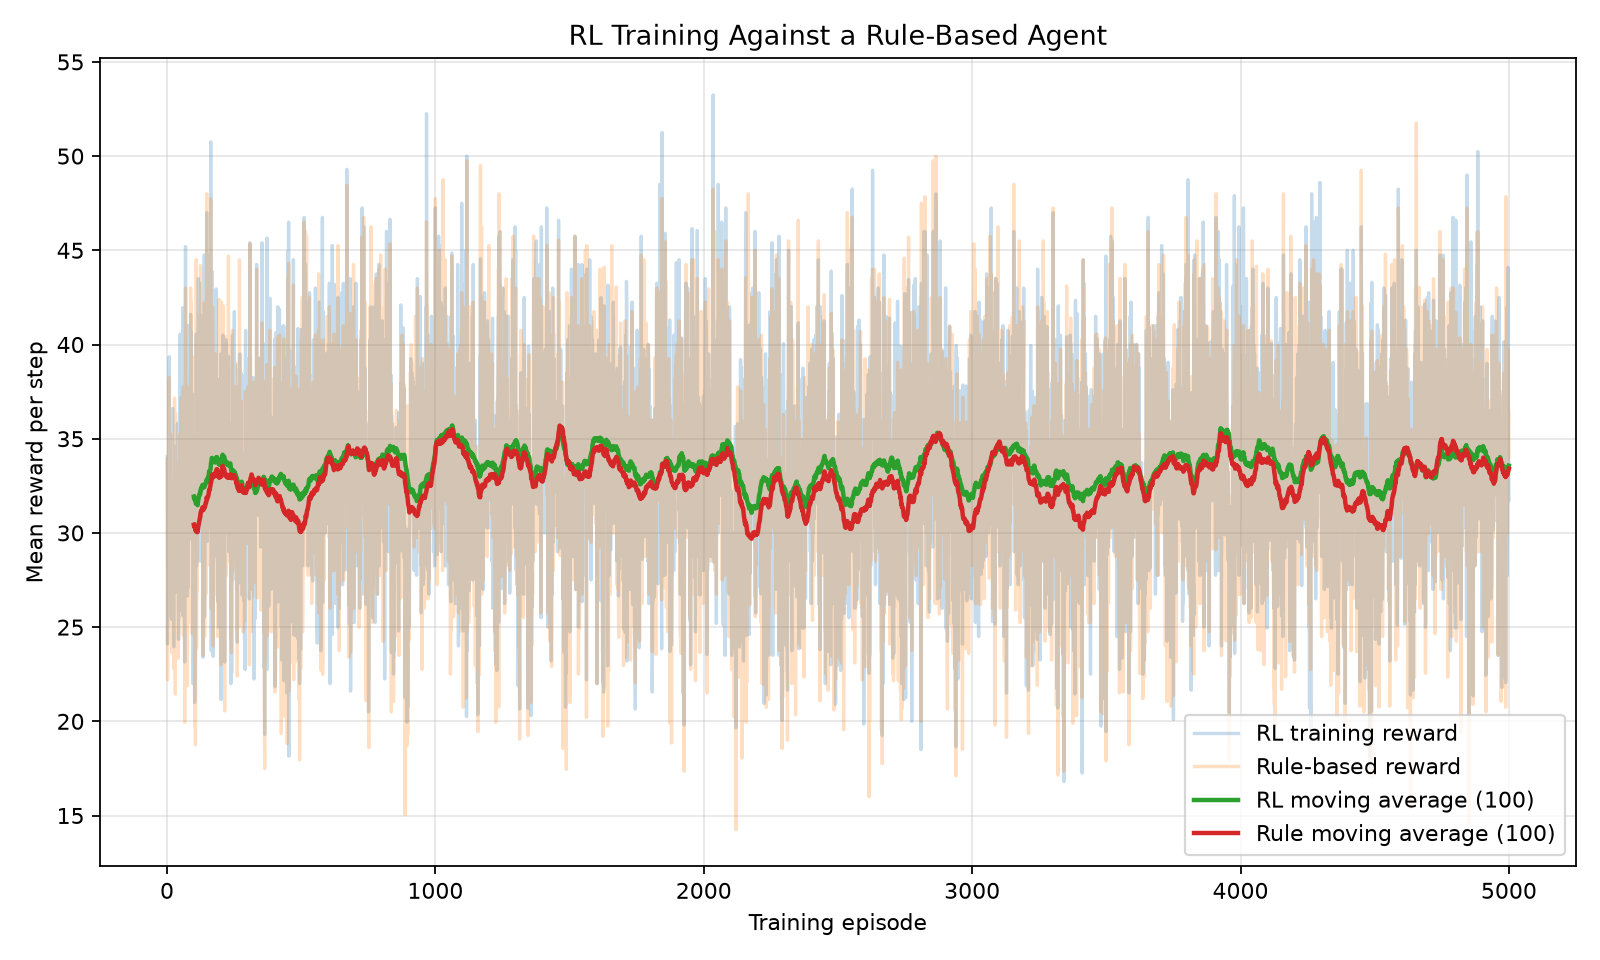

agent02_results/learning_rate_comparison.png


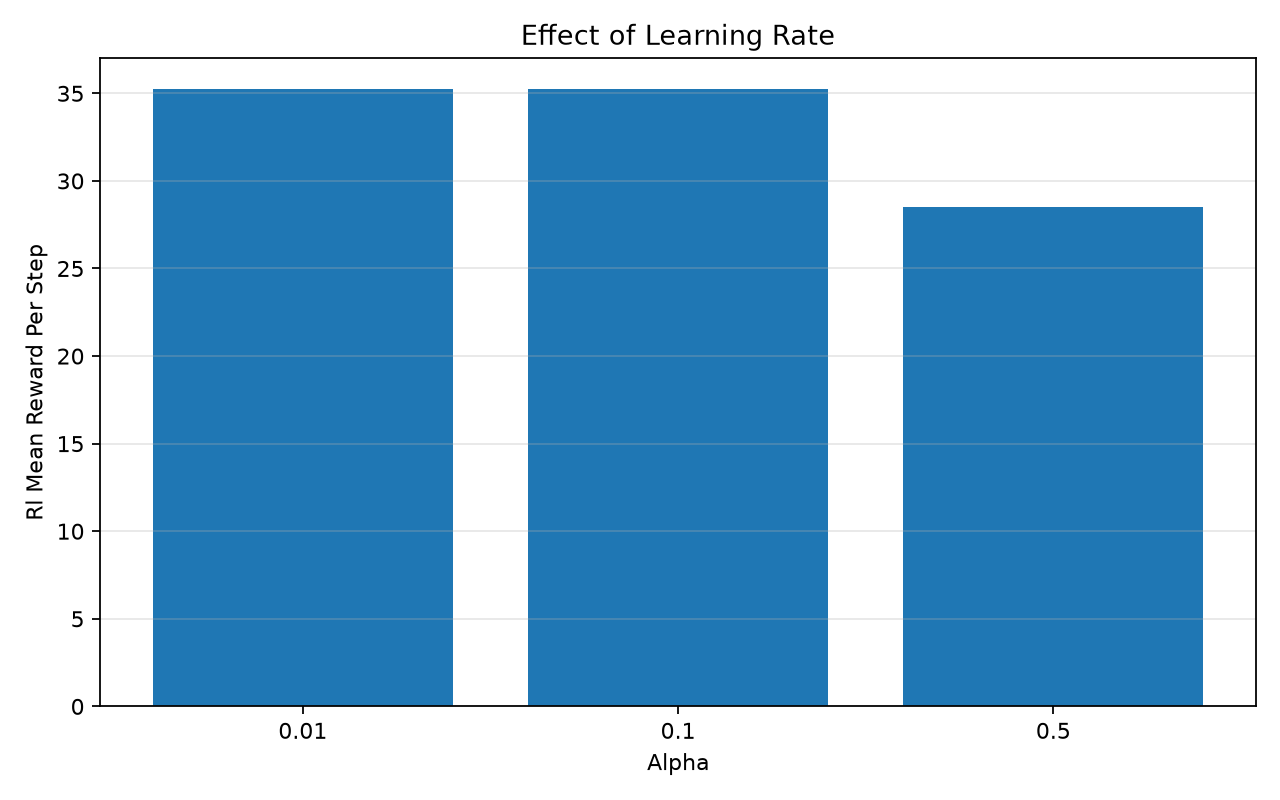

agent02_results/exploration_comparison.png


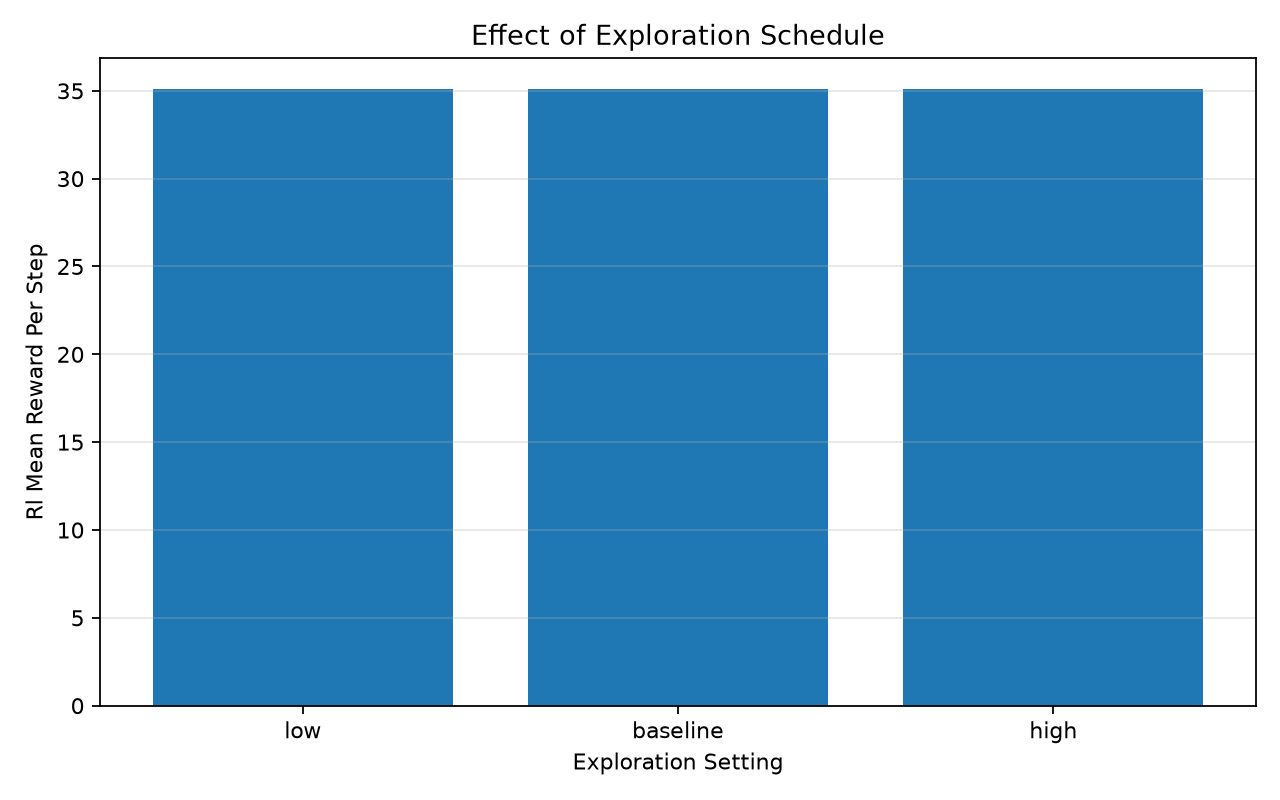

extra_results\alpha_curves.png


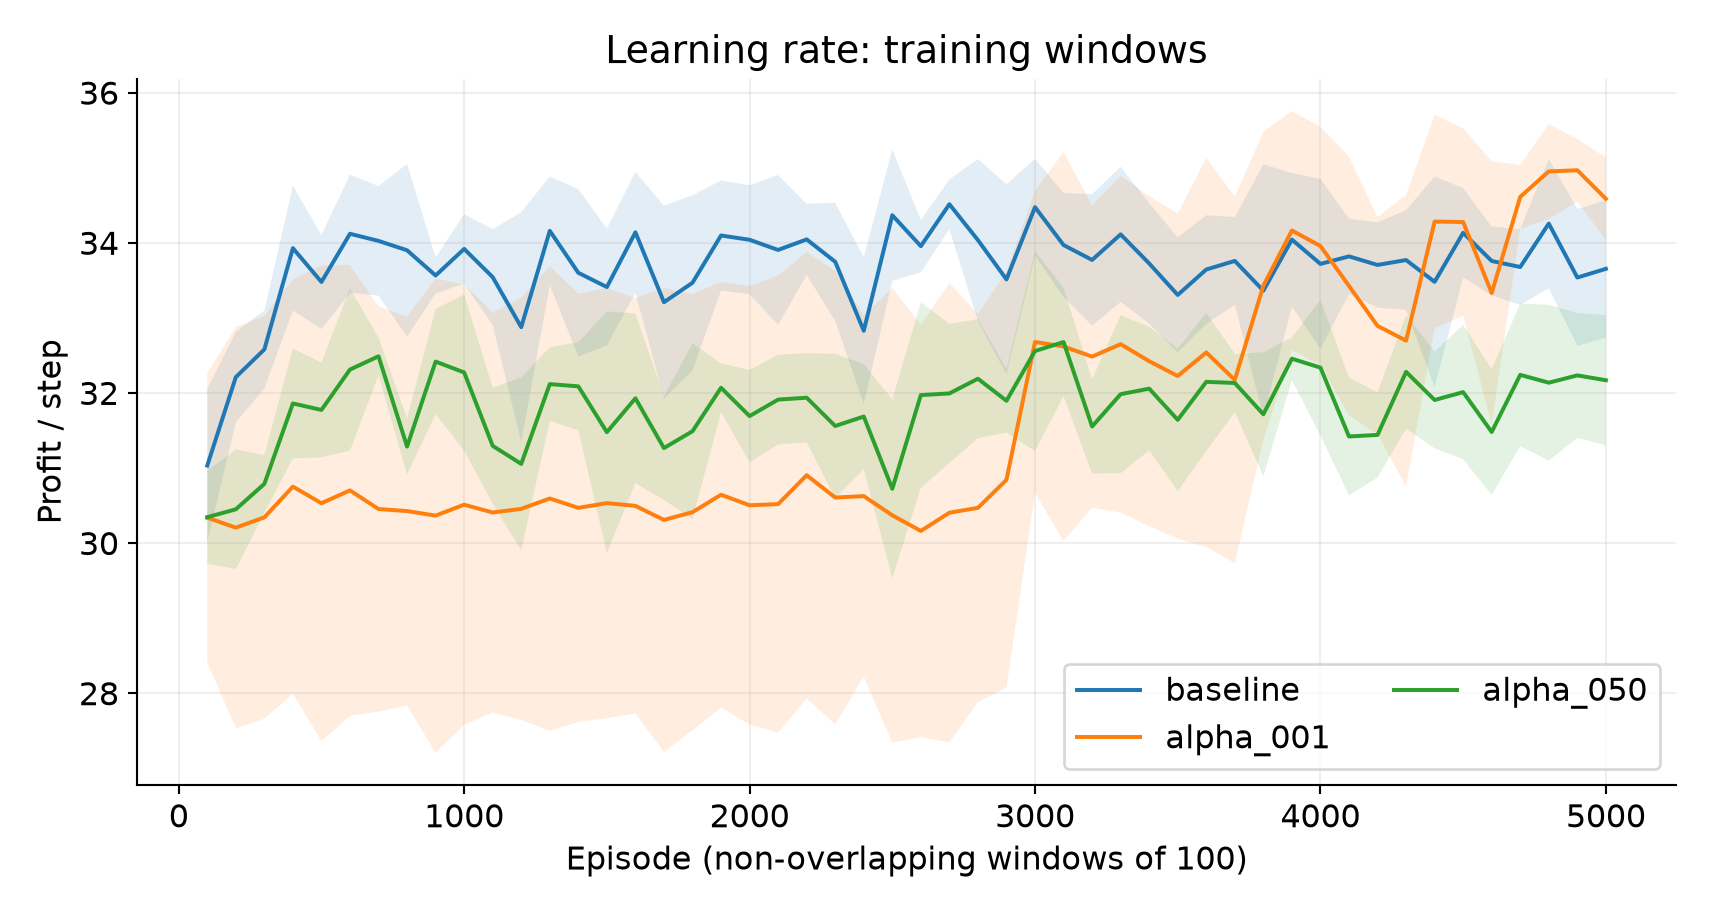

extra_results\exploration_curves.png


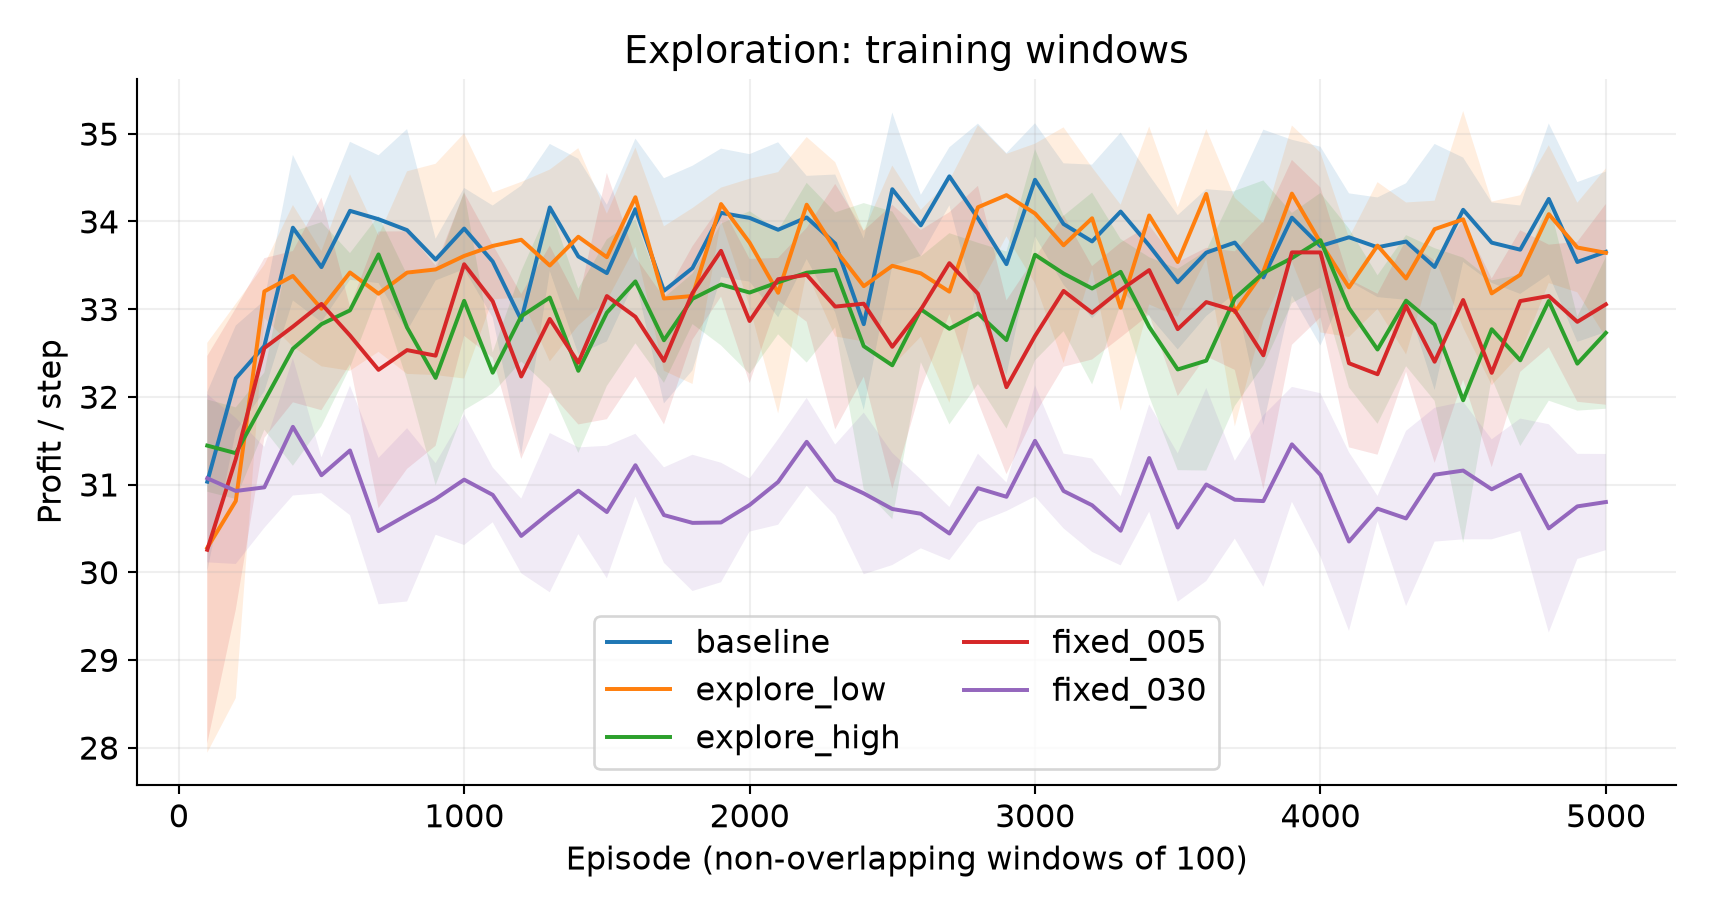

extra_results\evaluation_ci.png


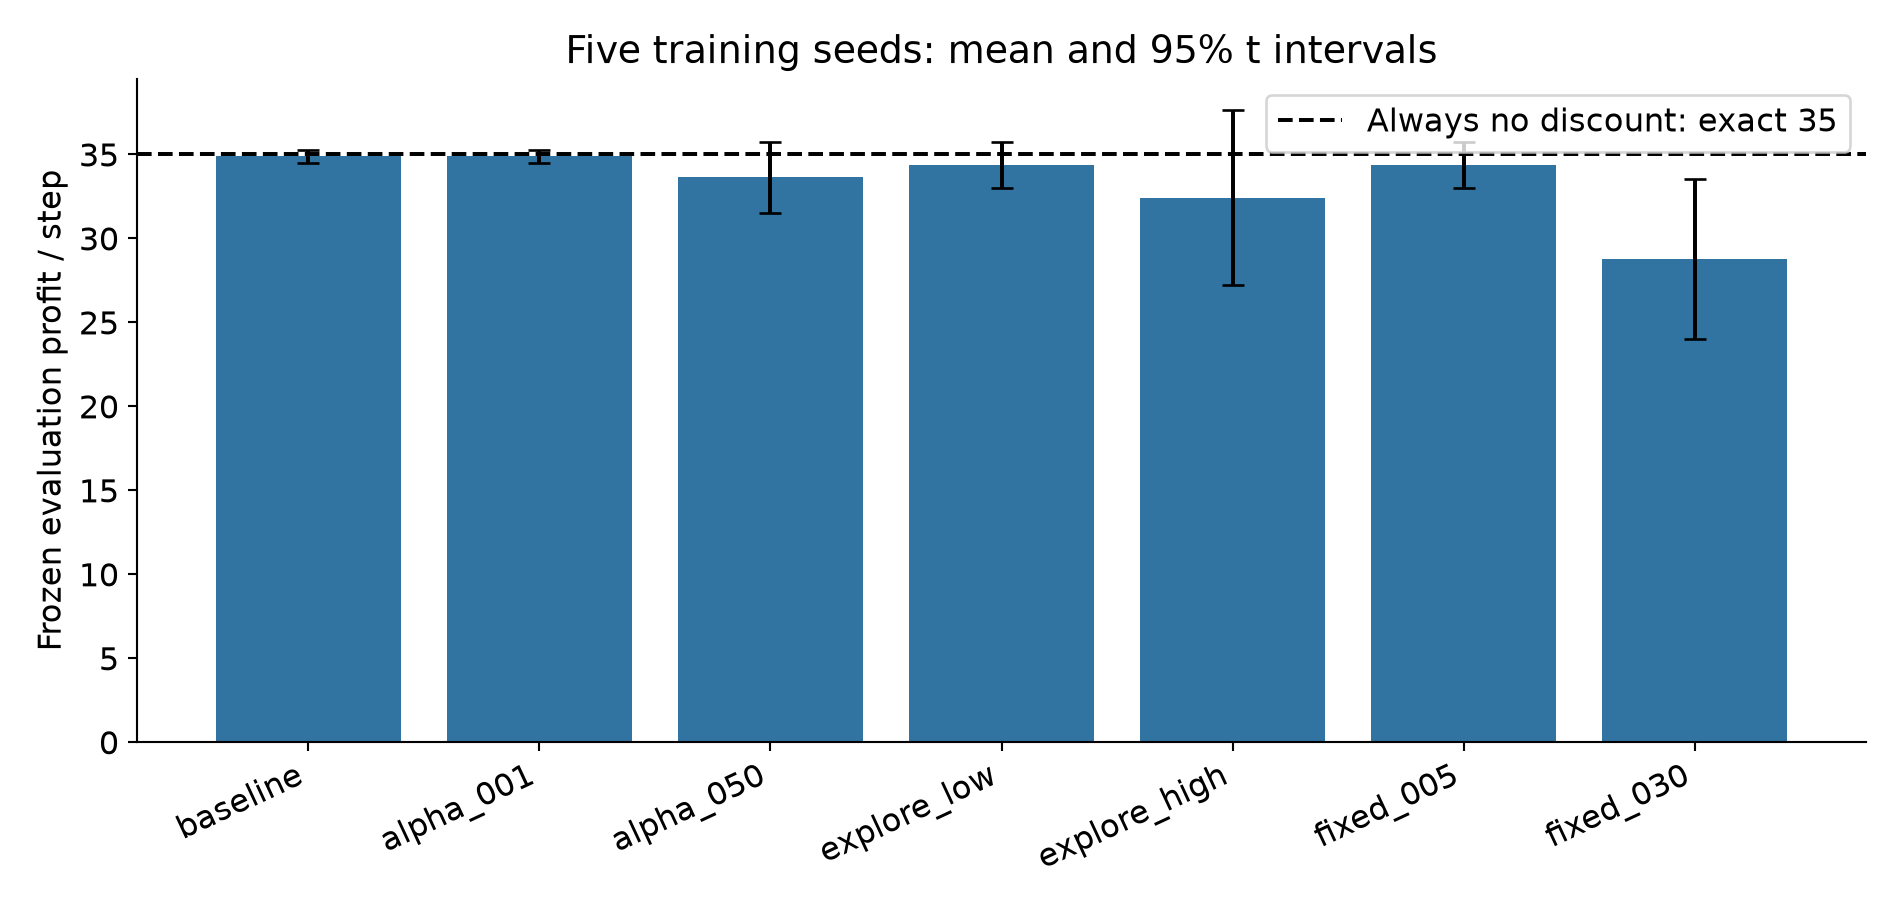

extra_results\seed_variation.png


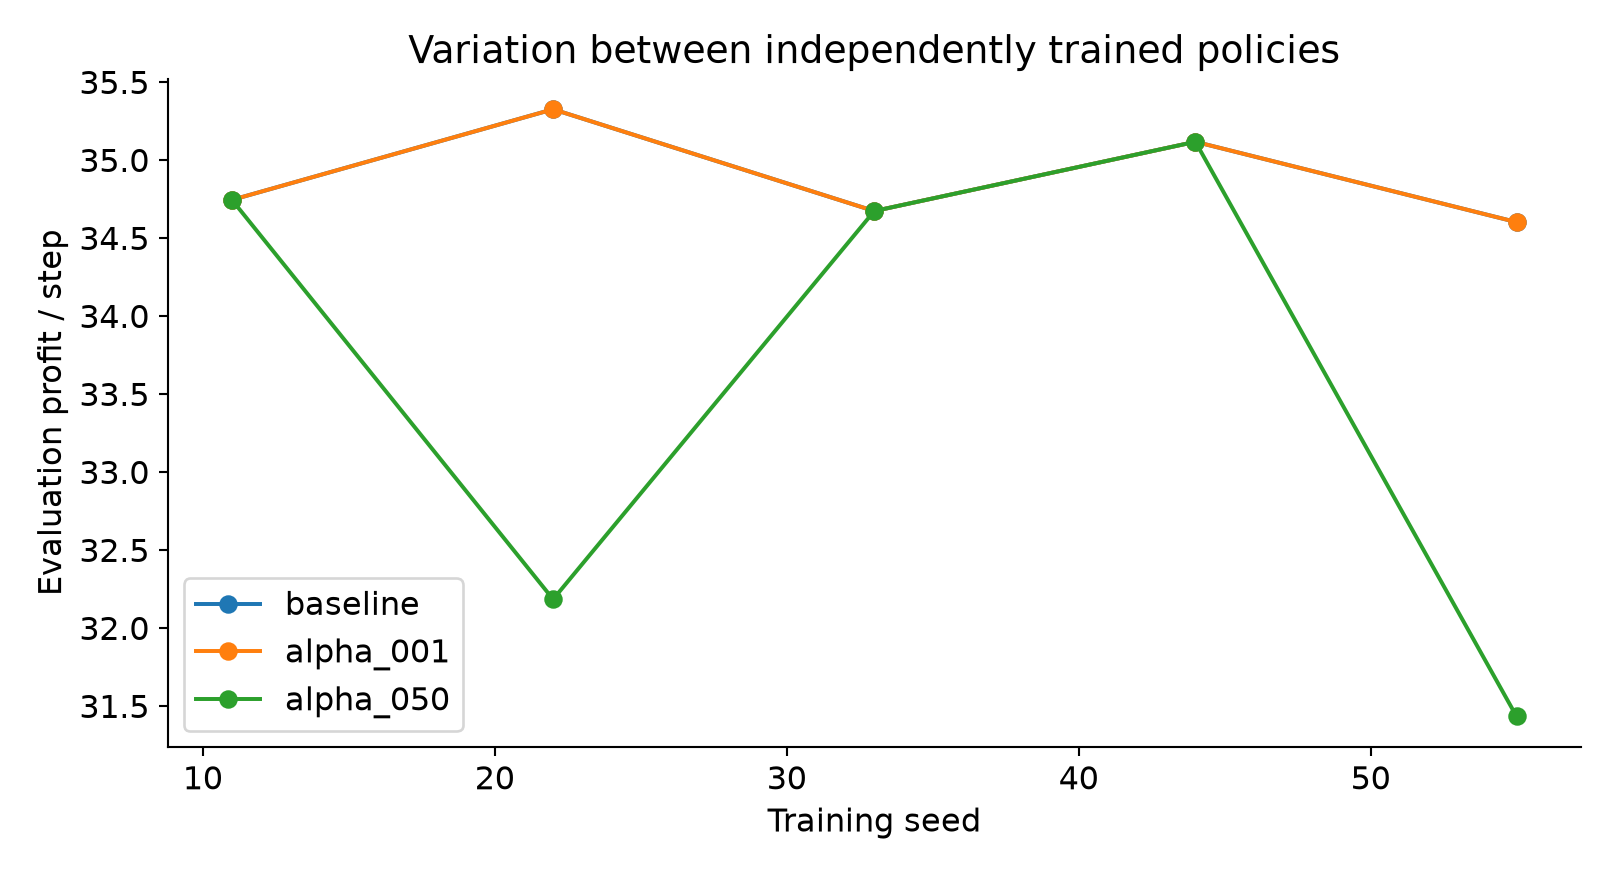

extra_results\robustness.png


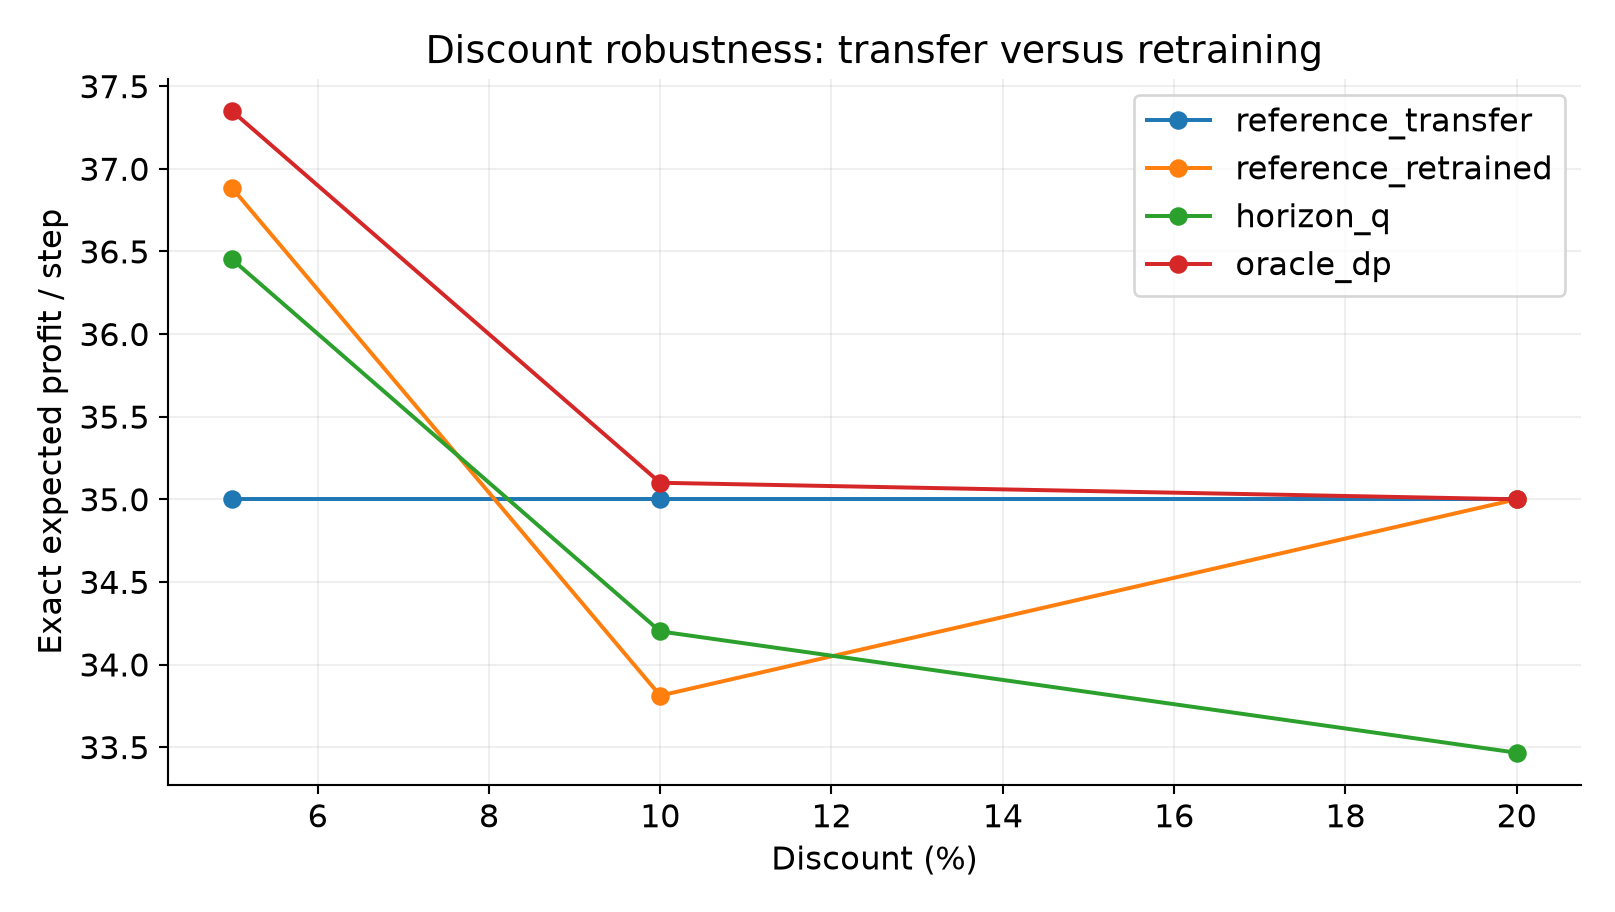

extra_results\oracle_gap.png


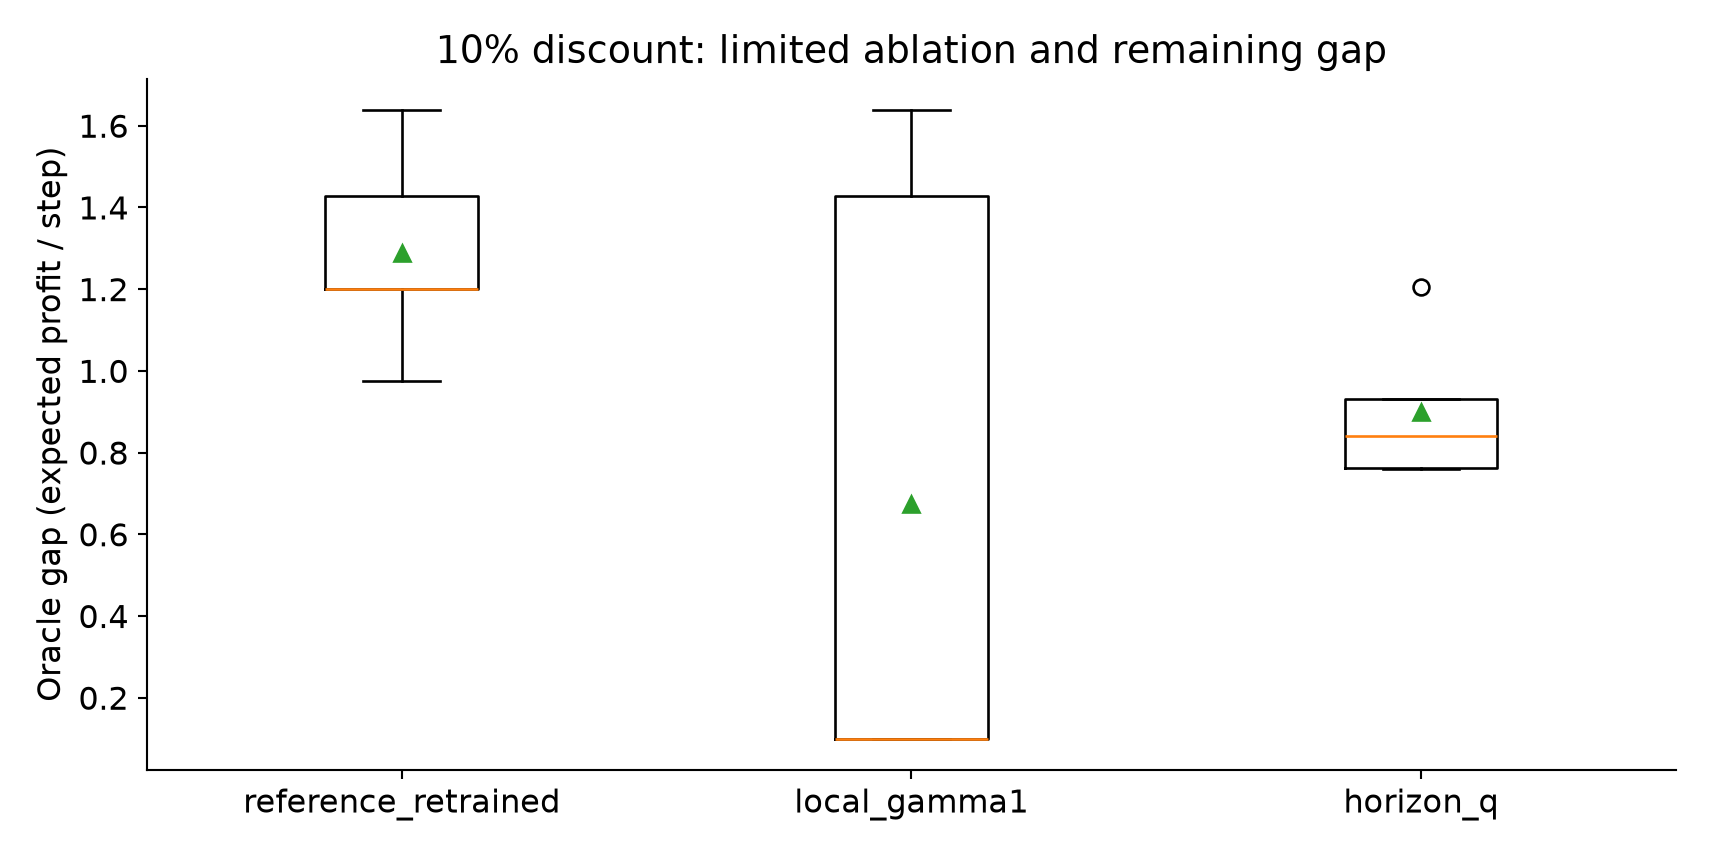

extra_results\q_heatmap.png


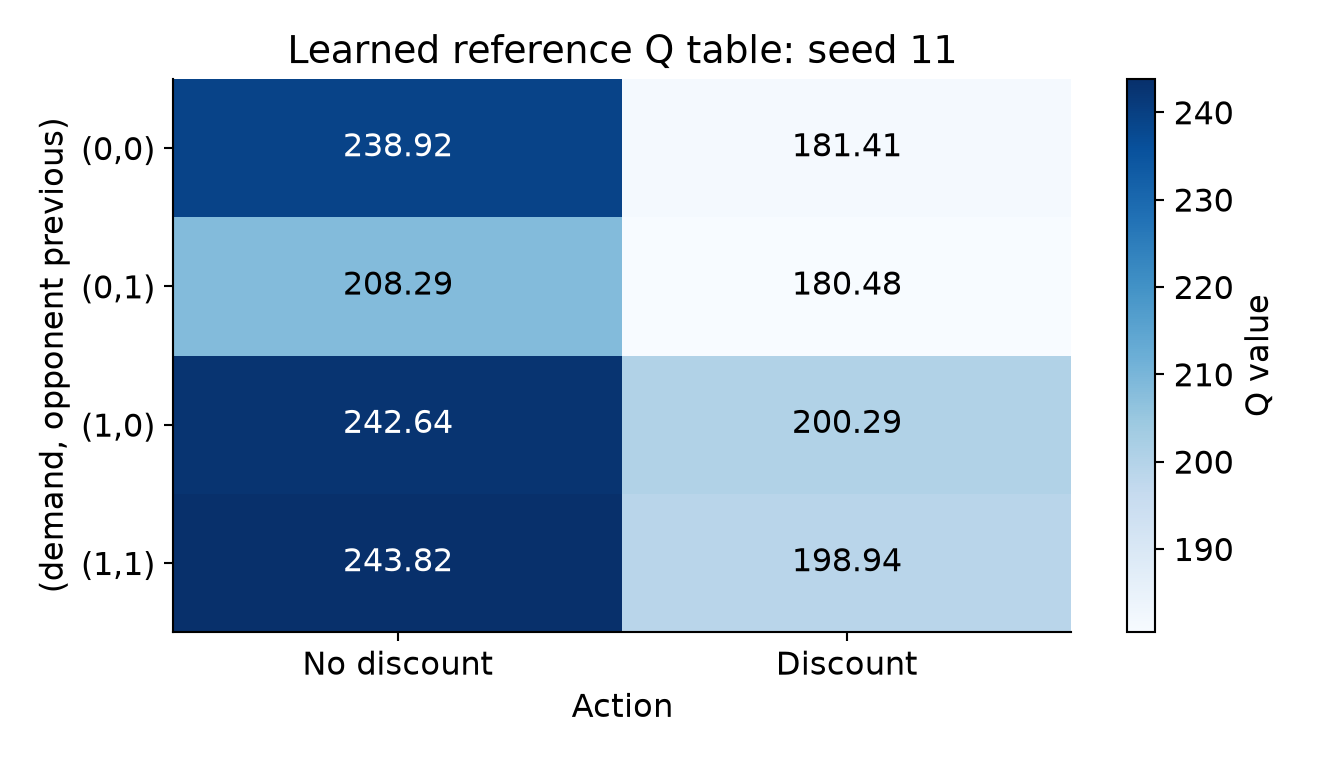

extra_results\epsilon_schedules.png


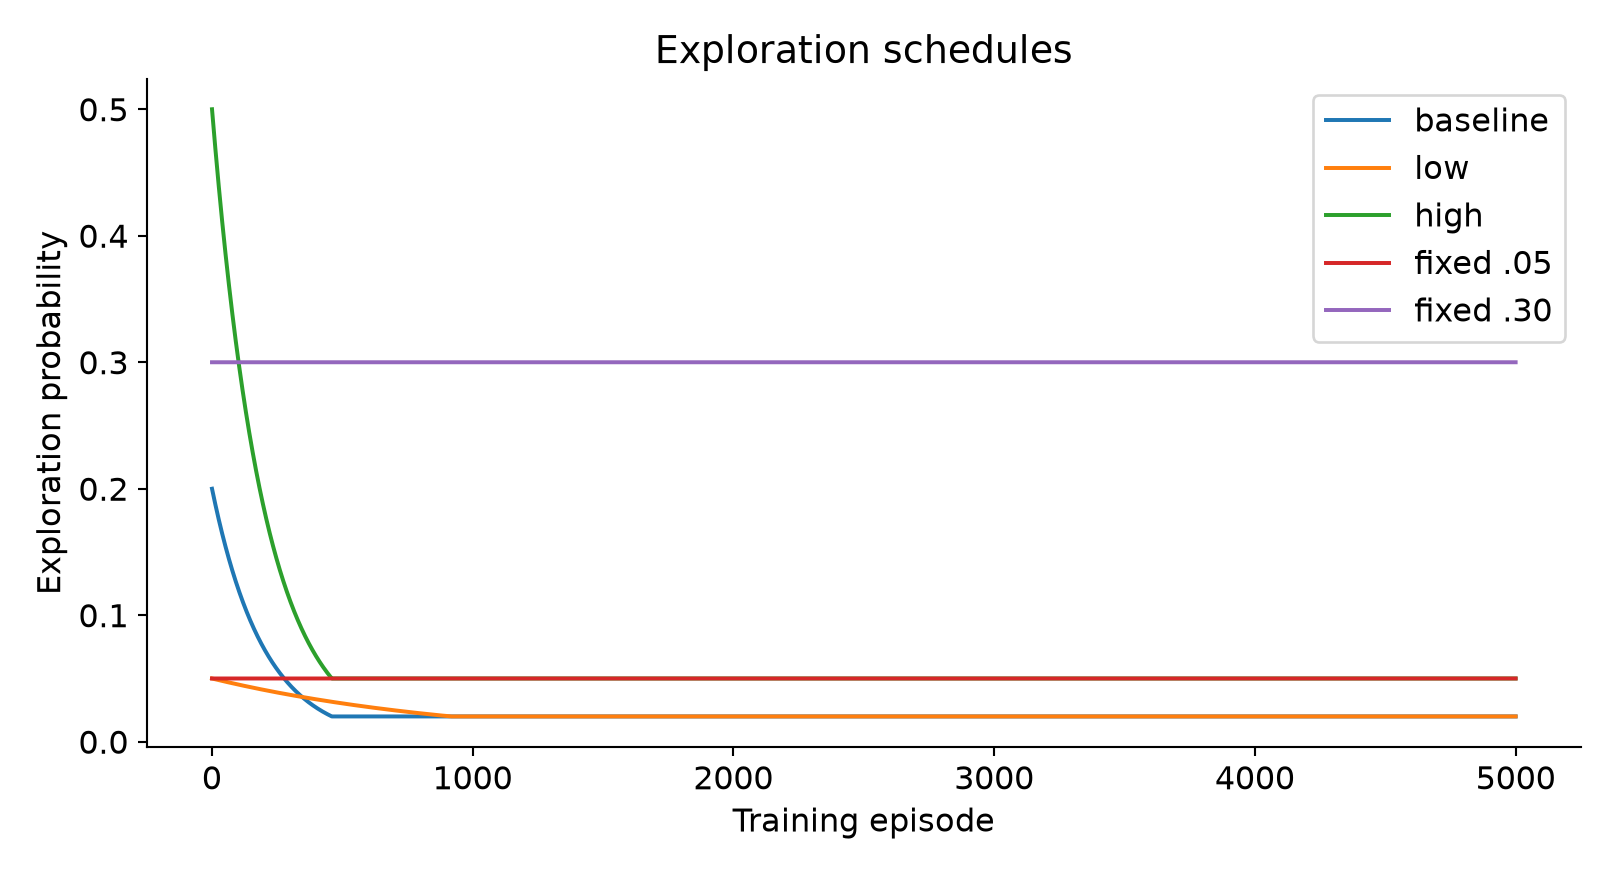

In [19]:
import csv

def load_numeric_log(path):
    """Reload measured CSV records so plots can be rerun without training."""
    with open(path,encoding='utf-8',newline='') as file:
        rows = list(csv.DictReader(file))
    for row in rows:
        for key,value in row.items():
            if key not in ('setting','agent'):
                row[key] = float(value)
    return rows

cfg = Config()
extra_dir = Path('extra_results')
controlled_runs = load_numeric_log(extra_dir/'controlled_runs.csv')
training_windows = load_numeric_log(extra_dir/'training_windows.csv')
robustness_runs = load_numeric_log(extra_dir/'robustness_runs.csv')
figure_paths = make_figures(cfg,extra_dir,controlled_runs,training_windows,robustness_runs)
from IPython.display import display, Image
for path in ['agent02_results/episode_rewards.png','agent02_results/learning_rate_comparison.png','agent02_results/exploration_comparison.png'] + figure_paths:
    print(path)
    display(Image(filename=path))

## 23 Kiểm thử và lưu thông tin tái lập

Kiểm thử Q, terminal, luật, seed, evaluation đóng băng, config sai và oracle; ba trường hợp lỗi đầu vào phải được chặn. File test là phụ trợ kiểm chứng; các cell thí nghiệm tự chứa đầy đủ thuật toán.

<!-- coursework-vietnamese-guide:agents-essay:v1 -->

### Hướng dẫn đọc cell code 23: Kiểm tra tự động và ghi xác nhận

unittest discover work/test_agent02.py rồi chạy suite, assert thành công; lưu run_manifest.json gồm phiên bản, config, seeds, số test/failure và số run. Các test kiểm ví dụ TD, terminal, bảng luật, seed, đánh giá không đổi Q, DP hai bước và trạng thái thiếu lịch sử. Đây là lệnh thực thi kiểm tra nếu chạy notebook; trong đợt bổ sung giải thích hiện tại chỉ giữ nguyên mã/output, không chạy lại.

**Dữ liệu và kết quả trong phiên chạy.** Các tên được gán ở mức cell gồm `suite`, `test_result`, `manifest`. Chúng được giữ trong kernel cho các cell sau; đọc cell từ trên xuống để biết tên nào là dữ liệu vào đã có và tên nào vừa được tạo. Nếu khởi động lại kernel thì cần nạp lại các cell chuẩn bị phụ thuộc trước khi dùng những biến này.

**Cách đọc đầu ra.** `print`/`display` đưa bảng hoặc thông tin ra màn hình; giá trị `return` là kết quả để nơi gọi sử dụng. `assert` chỉ dừng khi điều kiện cụ thể trong mã sai; các ca đi qua không phải bằng chứng rằng mọi đầu vào đều đúng. Cell có mã cập nhật trạng thái, học hoặc ghi file (có thể nằm trong helper chỉ chạy khi được gọi); các thao tác được mô tả ở phần trên. Chỉ đọc notebook không tự thực hiện chúng.


In [23]:
import unittest
suite = unittest.defaultTestLoader.discover('work',pattern='test_agent02.py')
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()
manifest = {'python':sys.version,'platform':platform.platform(),'numpy':np.__version__,
'matplotlib':plt.matplotlib.__version__,'seeds':SEEDS,'config':vars(cfg),
'code_cells':23,'tests_run':test_result.testsRun,'test_failures':len(test_result.failures),
'controlled_runs':len(controlled_runs),'robustness_runs':len(robustness_runs)}
(extra_dir/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print(json.dumps(manifest,indent=2))

test_exact_reference_policy (test_agent02.ExtensionTests.test_exact_reference_policy) ... 

ok


test_failure_invalid_config (test_agent02.ExtensionTests.test_failure_invalid_config) ... 

ok


test_horizon_terminal (test_agent02.ExtensionTests.test_horizon_terminal) ... 

ok


... (20 outputs left out)

test_terminal_no_bootstrap (test_agent02.ReferenceTests.test_terminal_no_bootstrap) ... 

ok


----------------------------------------------------------------------
Ran 14 tests in 0.141s

OK


{
  "python": "3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy": "2.5.2",
  "matplotlib": "3.11.1",
  "seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "config": {
    "episodes": 5000,
    "steps_per_episode": 20,
    "alpha": 0.1,
    "gamma": 0.9,
    "epsilon_start": 0.2,
    "epsilon_min": 0.02,
    "epsilon_decay": 0.995,
    "price": 10.0,
    "unit_cost": 5.0,
    "discount_rate": 0.2,
    "low_demand_customers": 10,
    "high_demand_customers": 20,
    "seed": 42,
    "evaluation_episodes": 500,
    "output_dir": "agent02_results"
  },
  "code_cells": 23,
  "tests_run": 14,
  "test_failures": 0,
  "controlled_runs": 35,
  "robustness_runs": 65
}


## Kết luận đọc kết quả

Đọc reward evaluation cùng tỷ lệ discount và Q-table; không kết luận RL luôn tốt hơn luật. Training reward chịu ảnh hưởng exploration. Kỳ vọng exact giúp tách lỗi policy khỏi nhiễu doanh số. Agent cải tiến thay cả state, horizon, gamma và learning rate nên chỉ có thể kết luận về gói cải tiến; local gamma=1 là kiểm tra một yếu tố, chưa đủ ablation toàn phần.

Tài liệu chính: assignment_Agent02_due_29.10.pdf và agent02_complementary_code.pdf; agent02_code.tex chứa Python thực thi. Ba PDF còn lại cung cấp nền tảng RL và MAS, không buộc thay bài AGENT02 bằng bài lab LLM hay PyTorch.